# Experimentación y resultados

**Proyecto:** predicción de la tasa mensual de denuncias policiales por distrito en el Perú.

**Entrada:** `dataset_distrito_mes.csv`.

**Modelos:** KNN, Random Forest y Gradient Boosting, comparados contra una línea base ingenua (la tasa del mes anterior).

**Qué pregunta responde este notebook.** Nuestra hipótesis es que, usando el historial de denuncias, la población y la pobreza del distrito, al menos uno de los tres modelos predice la tasa del mes siguiente con menos error que la regla simple de "el próximo mes será igual a este". Todo el notebook está armado para responder eso de forma honesta: sin usar información del futuro para entrenar y sin tocar el año de prueba (2025) hasta el final.

**Contenido:** 1) Carga de datos · 2) Preprocesamiento · 3) Análisis exploratorio · 4) Separación train / validation / test · 5) Línea base · 6) Evaluación de los algoritmos · 7) Optimización de hiperparámetros con validación cruzada temporal · 8) Entrenamiento final y prueba en 2025 · 9) Real vs. predicho · 10) Análisis del error · 11) Importancia de variables · 12) Referencias adicionales · 13) Resumen

In [1]:
# Cargar librerias y modulos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.neighbors import KNeighborsRegressor        # KNN para regresion
from sklearn.ensemble import RandomForestRegressor       # Random Forest para regresion
from sklearn.ensemble import GradientBoostingRegressor   # Gradient Boosting para regresion
from sklearn.linear_model import Ridge                   # Ridge (solo como referencia adicional)

from sklearn.preprocessing import StandardScaler         # escalamiento estandar
from sklearn.pipeline import Pipeline                    # para armar pipelines (escalador + modelo)
from sklearn.base import clone                           # para copiar un modelo sin entrenar

from sklearn.model_selection import GridSearchCV         # busqueda de hiperparametros en cuadricula

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score   # metricas de desempeño

warnings.simplefilter(action='ignore', category=FutureWarning)
sns.set(style="whitegrid")
pd.set_option('display.float_format', lambda x: '%.3f' % x)

seed = 42   # semilla para el generador aleatorio (para reproductibilidad)

## 1. Carga de datos

Se lee el dataset integrado a nivel distrito-mes generado en el notebook 01. Cada fila es un distrito en un mes, con sus denuncias totales, su población proyectada, su crecimiento poblacional, su pobreza monetaria y la tasa de denuncias por cada 100 000 habitantes. Todo el preprocesamiento se trabaja sobre el objeto `df`.

In [2]:
# En Colab: subir el archivo a /content (o cambiar la ruta por la de Drive)
filename = 'dataset_distrito_mes.csv'

df = pd.read_csv(filename, dtype={'UBIGEO': str}, parse_dates=['FECHA'])
df.head()

,UBIGEO,ANIO,MES,FECHA,DENUNCIAS_TOTALES,MODALIDADES_REGISTRADAS,POBLACION_PROYECTADA,CRECIMIENTO_POBLACIONAL_PCT,POBREZA_INF,POBREZA_SUP,POBREZA_PUNTO_MEDIO_PCT,GRUPO_ROBUSTO,UBICACION_POBREZA,TASA_DENUNCIAS_100K
0,010101,2018,1,2018-01-01,152,6,36602.000,NaN,5.774,12.296,9.035,19.000,1747.000,415.278
1,010101,2018,2,2018-02-01,153,6,36602.000,NaN,5.774,12.296,9.035,19.000,1747.000,418.010
2,010101,2018,3,2018-03-01,150,7,36602.000,NaN,5.774,12.296,9.035,19.000,1747.000,409.814
3,010101,2018,4,2018-04-01,139,5,36602.000,NaN,5.774,12.296,9.035,19.000,1747.000,379.761
4,010101,2018,5,2018-05-01,130,5,36602.000,NaN,5.774,12.296,9.035,19.000,1747.000,355.172


In [3]:
df.shape

(124794, 14)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 124794 entries, 0 to 124793
Data columns (total 14 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   UBIGEO                       124794 non-null  str           
 1   ANIO                         124794 non-null  int64         
 2   MES                          124794 non-null  int64         
 3   FECHA                        124794 non-null  datetime64[us]
 4   DENUNCIAS_TOTALES            124794 non-null  int64         
 5   MODALIDADES_REGISTRADAS      124794 non-null  int64         
 6   POBLACION_PROYECTADA         124790 non-null  float64       
 7   CRECIMIENTO_POBLACIONAL_PCT  113384 non-null  float64       
 8   POBREZA_INF                  124633 non-null  float64       
 9   POBREZA_SUP                  124633 non-null  float64       
 10  POBREZA_PUNTO_MEDIO_PCT      124633 non-null  float64       
 11  GRUPO_ROBUSTO                124633 n

In [5]:
# Veamos estadisticos basicos
df.describe()

,ANIO,MES,FECHA,DENUNCIAS_TOTALES,MODALIDADES_REGISTRADAS,POBLACION_PROYECTADA,CRECIMIENTO_POBLACIONAL_PCT,POBREZA_INF,POBREZA_SUP,POBREZA_PUNTO_MEDIO_PCT,GRUPO_ROBUSTO,UBICACION_POBREZA,TASA_DENUNCIAS_100K
count,124794.000,124794.000,124794,124794.000,124794.000,124790.000,113384.000,124633.000,124633.000,124633.000,124633.000,124633.000,124790.000
mean,2021.987,6.391,2022-06-08 16:24:36.070964,58.977,2.958,25887.382,-0.225,21.948,39.686,30.817,12.435,1042.912,172.086
min,2018.000,1.000,2018-01-01 00:00:00,1.000,1.000,128.000,-46.661,0.000,0.115,0.057,1.000,2.000,1.354
25%,2020.000,3.000,2020-06-01 00:00:00,2.000,1.000,2794.000,-1.410,10.790,24.018,17.124,8.000,586.000,64.579
50%,2022.000,6.000,2022-07-01 00:00:00,7.000,3.000,6877.000,0.053,20.189,39.848,30.285,12.000,1079.000,132.836
75%,2024.000,9.000,2024-07-01 00:00:00,28.000,4.000,18291.000,1.186,31.026,55.743,43.664,16.000,1525.000,231.481
max,2026.000,12.000,2026-07-01 00:00:00,3897.000,7.000,1300785.000,65.907,74.592,87.404,80.998,28.000,1874.000,3926.282
std,2.414,3.437,NaN,192.955,1.759,70972.845,2.715,14.140,19.869,16.761,5.037,539.340,161.224


## 2. Preprocesamiento

### 2.1 Valores nulos

In [6]:
null_pct = (df.isna().sum()/len(df)*100).sort_values(ascending=False)
print("Porcentaje de nulos por columna")
print(null_pct)

Porcentaje de nulos por columna
CRECIMIENTO_POBLACIONAL_PCT   9.143
GRUPO_ROBUSTO                 0.129
POBREZA_PUNTO_MEDIO_PCT       0.129
POBREZA_SUP                   0.129
POBREZA_INF                   0.129
UBICACION_POBREZA             0.129
POBLACION_PROYECTADA          0.003
TASA_DENUNCIAS_100K           0.003
MODALIDADES_REGISTRADAS       0.000
DENUNCIAS_TOTALES             0.000
ANIO                          0.000
UBIGEO                        0.000
FECHA                         0.000
MES                           0.000
dtype: float64


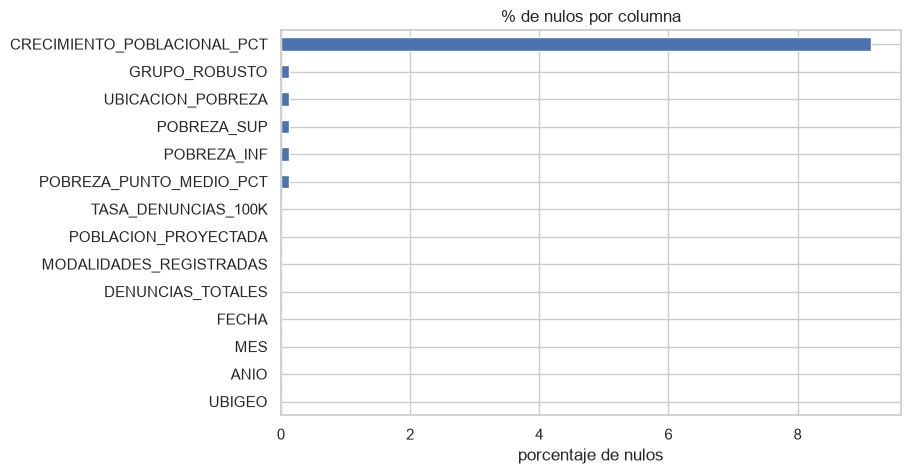

In [7]:
null_pct.sort_values(ascending=True).plot(kind='barh', figsize=[8,5])
plt.title('% de nulos por columna')
plt.xlabel('porcentaje de nulos')
plt.show()

Tratamiento de los nulos:

- **Tasa de denuncias / población:** sin población no se puede calcular la tasa, así que esas filas se eliminan.
- **Crecimiento poblacional:** el de 2018 no se puede calcular (no hay año anterior). Se completa con el de 2019 del mismo distrito.
- **Pobreza:** los distritos sin dato de pobreza se excluyen (no se inventa un valor).

In [8]:
# Filas sin tasa (no tienen poblacion proyectada)
df = df.dropna(subset=['TASA_DENUNCIAS_100K'])

# Crecimiento poblacional de 2018: se completa con el siguiente valor disponible del mismo distrito
df['CRECIMIENTO_POBLACIONAL_PCT'] = df.groupby('UBIGEO')['CRECIMIENTO_POBLACIONAL_PCT'].bfill()

# Distritos sin dato de pobreza
df = df.dropna(subset=['POBREZA_PUNTO_MEDIO_PCT'])

df.shape

(124633, 14)

**Qué se perdió con esta limpieza.** De las 124 794 filas distrito-mes, solo 4 no tenían población (y por tanto tasa) y 161 no tenían dato de pobreza, así que la limpieza casi no reduce los datos. El nulo más frecuente era el crecimiento poblacional de 2018 (11 410 filas), que no se elimina sino que se completa con el valor de 2019 del mismo distrito.

### 2.2 Selección de columnas

Nos quedamos solo con las columnas que se usarán para construir las variables del modelo y les damos nombres más cortos.

In [9]:
df = df[['UBIGEO', 'FECHA', 'TASA_DENUNCIAS_100K', 'POBLACION_PROYECTADA',
         'CRECIMIENTO_POBLACIONAL_PCT', 'POBREZA_PUNTO_MEDIO_PCT']]

df = df.rename(columns={'TASA_DENUNCIAS_100K': 'TASA_T',
                        'CRECIMIENTO_POBLACIONAL_PCT': 'CRECIMIENTO_POB',
                        'POBREZA_PUNTO_MEDIO_PCT': 'POBREZA'})
df.head()

,UBIGEO,FECHA,TASA_T,POBLACION_PROYECTADA,CRECIMIENTO_POB,POBREZA
0,010101,2018-01-01,415.278,36602.000,3.464,9.035
1,010101,2018-02-01,418.010,36602.000,3.464,9.035
2,010101,2018-03-01,409.814,36602.000,3.464,9.035
3,010101,2018-04-01,379.761,36602.000,3.464,9.035
4,010101,2018-05-01,355.172,36602.000,3.464,9.035


### 2.3 Malla completa distrito × mes

No todos los distritos registran denuncias todos los meses: en el archivo original, un mes sin denuncias registradas simplemente no aparece como fila.

**Por qué esto importa.** Las variables históricas se calculan "corriendo" la tasa una posición hacia atrás dentro de cada distrito. Si a un distrito le falta marzo, la fila anterior a abril sería febrero, y estaríamos llamando "mes anterior" a algo que ocurrió dos meses antes. Para evitarlo armamos una malla con **todos** los meses para cada distrito.

Los meses sin registro quedan como `NaN` y **no** como 0: no podemos saber si en ese mes realmente no hubo denuncias o si la comisaría no reportó, y poner un 0 sería inventar un dato.

In [10]:
meses = pd.date_range(df['FECHA'].min(), df['FECHA'].max(), freq='MS')
malla = pd.MultiIndex.from_product([df['UBIGEO'].unique(), meses], names=['UBIGEO', 'FECHA'])

df = df.set_index(['UBIGEO', 'FECHA']).reindex(malla).reset_index()
df.shape

(189211, 6)

### 2.4 Variables históricas (rezagos) y variable objetivo

Esta es la parte central del planteamiento. Para cada distrito, parados en el mes *t*:

- `TASA_T`: tasa del mes actual (*t*).
- `REZAGO_1`, `REZAGO_2`, `REZAGO_3`: tasa del distrito 1, 2 y 3 meses atrás.
- `PROM_MOVIL_3`: promedio de los últimos 3 meses (*t*, *t−1*, *t−2*). Suaviza los saltos de un mes puntual.
- `Y` (**target**): tasa del distrito en el **mes siguiente** (*t+1*).

**Por qué no hay fuga de información.** Todas las variables de entrada usan únicamente datos del mes *t* hacia atrás, y lo que se predice es *t+1*. Es exactamente la situación de uso real: al cierre de un mes, con lo que ya se conoce, se estima el mes que viene. El promedio móvil se calcula con `skipna=False` para que, si falta alguno de los tres meses, el resultado sea `NaN` en lugar de un promedio de menos meses.

In [12]:
tasa = df.groupby('UBIGEO')['TASA_T']

df['REZAGO_1'] = tasa.shift(1)
df['REZAGO_2'] = tasa.shift(2)
df['REZAGO_3'] = tasa.shift(3)
df['PROM_MOVIL_3'] = df[['TASA_T', 'REZAGO_1', 'REZAGO_2']].mean(axis=1, skipna=False)

# target: tasa del mes siguiente
df['Y'] = tasa.shift(-1)

### 2.5 Estacionalidad y población

- El mes que se quiere predecir se codifica con seno y coseno. Si usáramos el número del mes (1 a 12), el modelo vería a diciembre (12) y enero (1) como los meses más lejanos, cuando en realidad son consecutivos. Con seno y coseno los meses quedan sobre un círculo y diciembre y enero quedan "cerca".
- La población se pasa a logaritmo porque hay distritos de unos cientos de habitantes y otros de más de un millón. Sin el logaritmo, los pocos distritos enormes dominarían la escala (esto afecta sobre todo a KNN, que trabaja con distancias).
- `ANIO_OBJ` es el año del mes que se predice; se usa después para separar train / validation / test.

In [13]:
df['FECHA_OBJ'] = df['FECHA'] + pd.offsets.MonthBegin(1)   # mes que se predice (t+1)
df['ANIO_OBJ'] = df['FECHA_OBJ'].dt.year

df['MES_SIN'] = np.sin(2*np.pi*df['FECHA_OBJ'].dt.month/12)
df['MES_COS'] = np.cos(2*np.pi*df['FECHA_OBJ'].dt.month/12)

df['LOG_POBLACION'] = np.log(df['POBLACION_PROYECTADA'])

### 2.6 Filas modelables

Solo se usan las filas que tienen todas las variables y el target observados. En la práctica, esto significa que un distrito-mes entra al modelo solo si ese distrito registró denuncias en los cuatro meses anteriores seguidos y también en el mes siguiente.

In [14]:
features = ['TASA_T', 'REZAGO_1', 'REZAGO_2', 'REZAGO_3', 'PROM_MOVIL_3',   # historial
            'MES_SIN', 'MES_COS',                                           # estacionalidad
            'LOG_POBLACION', 'CRECIMIENTO_POB',                             # demografia
            'POBREZA']                                                      # pobreza
target = 'Y'

df = df.dropna(subset=features + [target]).reset_index(drop=True)

print('Filas modelables:', df.shape[0])
print('Distritos:', df['UBIGEO'].nunique())

Filas modelables: 88015
Distritos: 1440


In [15]:
# Revisemos que ya no queden nulos
df[features + [target]].isnull().sum()

TASA_T             0
REZAGO_1           0
REZAGO_2           0
REZAGO_3           0
PROM_MOVIL_3       0
MES_SIN            0
MES_COS            0
LOG_POBLACION      0
CRECIMIENTO_POB    0
POBREZA            0
Y                  0
dtype: int64

In [16]:
# Cantidad de datos y tasa por año del mes objetivo
df.groupby('ANIO_OBJ').agg(filas=('Y', 'size'),
                           distritos=('UBIGEO', 'nunique'),
                           tasa_media=('Y', 'mean'),
                           tasa_mediana=('Y', 'median'))

,filas,distritos,tasa_media,tasa_mediana
ANIO_OBJ,,,,
2018,5341,812,196.369,175.033
2019,9411,976,198.430,170.835
2020,9684,1051,167.501,134.910
2021,11126,1174,178.021,151.172
2022,11598,1181,193.319,161.368
2023,11525,1174,212.126,172.712
2024,11612,1187,210.943,170.596
2025,11313,1161,189.035,152.268
2026,6405,1076,178.093,138.504


**Cómo leer la tabla.** 2018 tiene menos filas porque sus primeros meses no tienen los rezagos completos y porque ese año menos distritos reportaban denuncias. Desde 2021 la cantidad de filas y de distritos por año es estable, lo que hace comparables a los años que usamos para validar (2022, 2023, 2024) y para probar (2025). Conviene fijarse también en la diferencia entre `tasa_media` y `tasa_mediana`: si la media es bastante mayor que la mediana, hay pocos distritos-mes con tasas muy altas que jalan el promedio hacia arriba.

## 3. Análisis exploratorio

#### Distribución de las variables

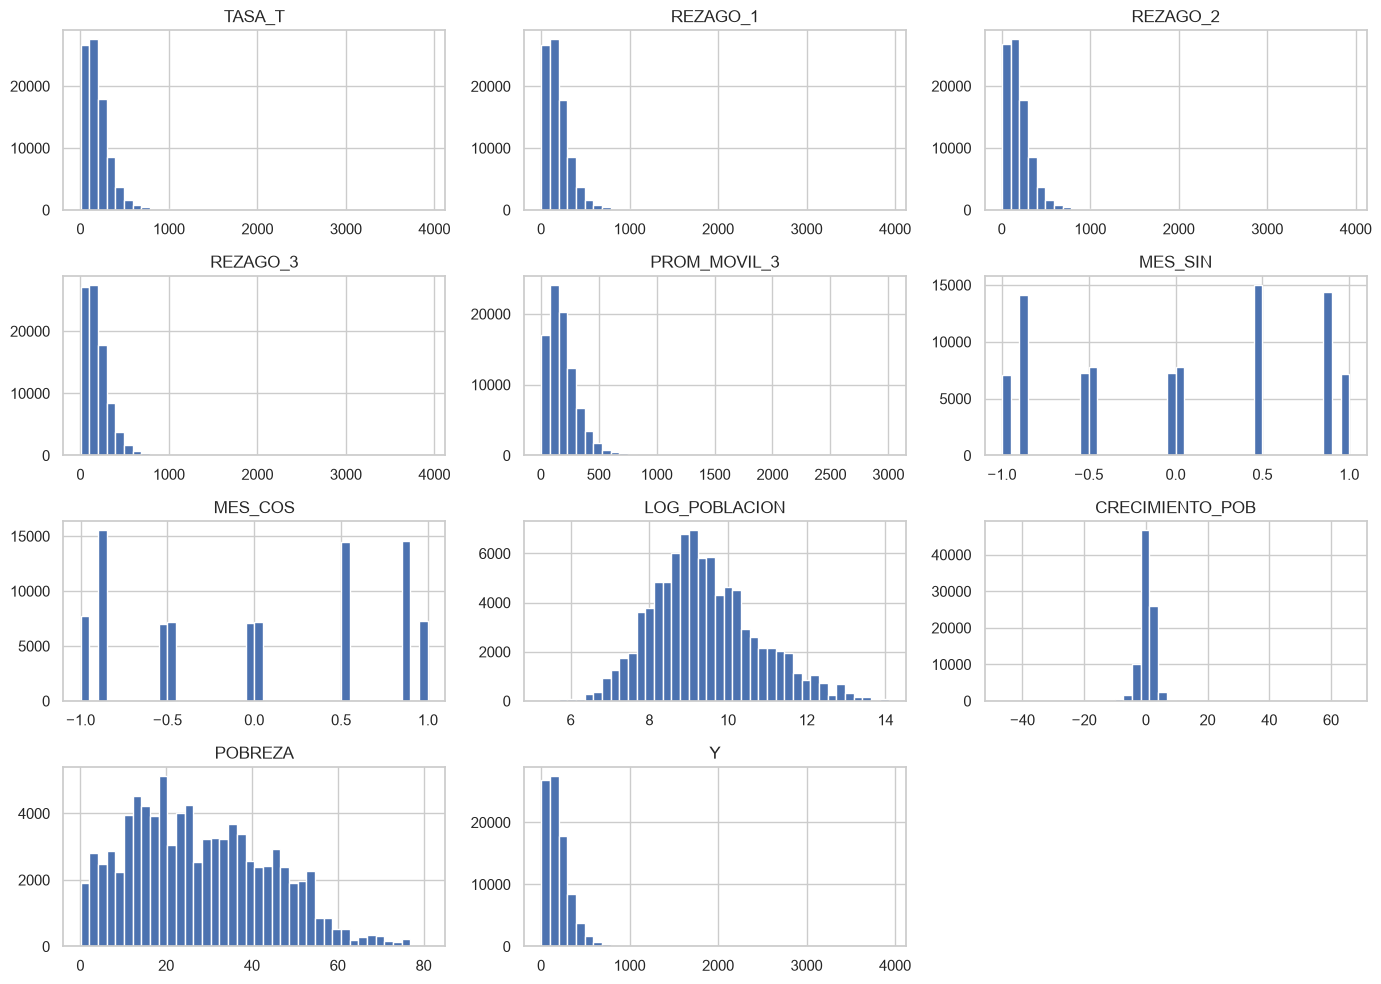

In [17]:
# muestra la distribucion de las variables
df[features + [target]].hist(figsize=[14,10], bins=40)
plt.tight_layout()
plt.show()

**Cómo leer la figura.** Las tasas (`TASA_T`, los rezagos, `PROM_MOVIL_3` e `Y`) tienen una cola larga hacia la derecha: la mayoría de distritos-mes tiene tasas bajas y unos pocos tienen tasas muy altas. Esto anticipa dos cosas: que el RMSE será bastante mayor que el MAE (porque castiga esos casos extremos) y que el error no será parejo entre distritos. `MES_SIN` y `MES_COS` solo toman los valores de los 12 meses, y `LOG_POBLACION` queda con una forma mucho más simétrica que la que tendría la población sin transformar.

#### Matriz de correlación

Permite ver qué variables se relacionan más con el target `Y` y cuáles están correlacionadas entre sí.

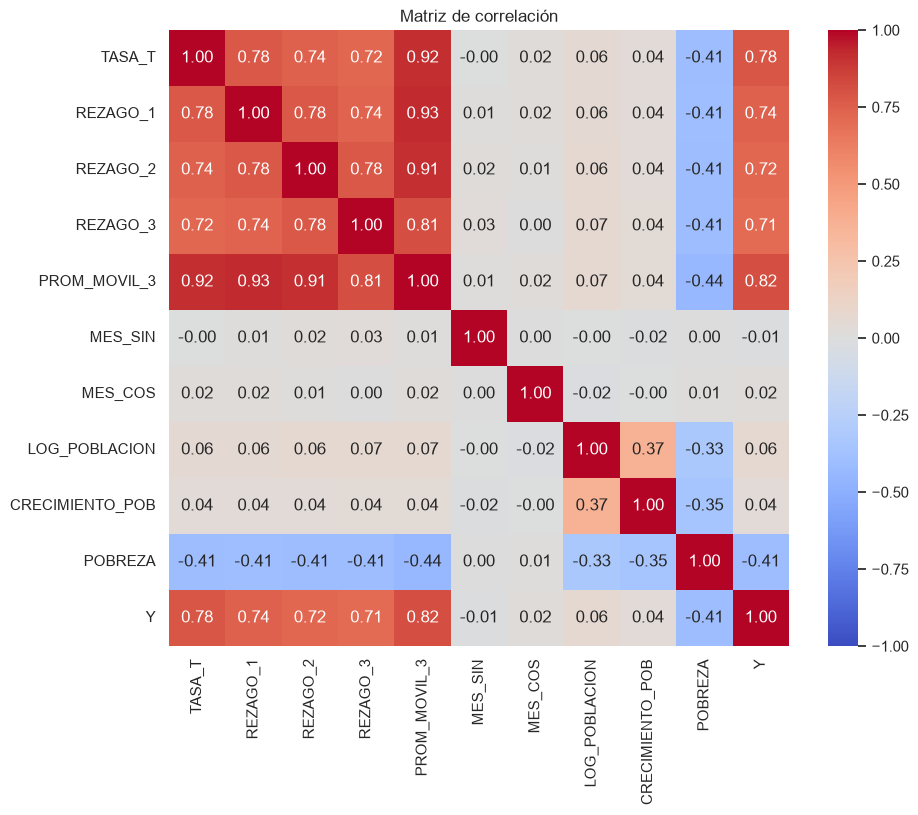

In [18]:
correlations = df[features + [target]].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlations, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Matriz de correlación')
plt.show()

In [19]:
# Correlacion de cada variable con el target, ordenada
correlations[target].drop(target).sort_values(ascending=False)

PROM_MOVIL_3       0.816
TASA_T             0.783
REZAGO_1           0.744
REZAGO_2           0.723
REZAGO_3           0.708
LOG_POBLACION      0.063
CRECIMIENTO_POB    0.037
MES_COS            0.020
MES_SIN           -0.015
POBREZA           -0.408
Name: Y, dtype: float64

**Cómo leer la figura.** La última fila/columna (`Y`) muestra la relación de cada variable con la tasa del mes siguiente. Dos lecturas importantes:

- Las variables de historial son las más correlacionadas con `Y`: la tasa de un distrito se parece mucho a la de sus meses anteriores. Por eso la base ingenua es un rival exigente.
- Las variables de historial también están muy correlacionadas **entre sí**, porque todas miden la tasa reciente del mismo distrito. Esto no perjudica a los modelos de árboles, pero sí obliga a leer con cuidado la importancia de variables (sección 11): el modelo puede repartir la importancia entre ellas de forma arbitraria.

Población, crecimiento y pobreza tienen una correlación lineal más baja con `Y`. Eso no significa que no aporten: la correlación solo mide relaciones lineales, y lo que aportan se mide directamente en la sección 11 quitándolas del modelo.

#### Boxplots (valores atípicos)

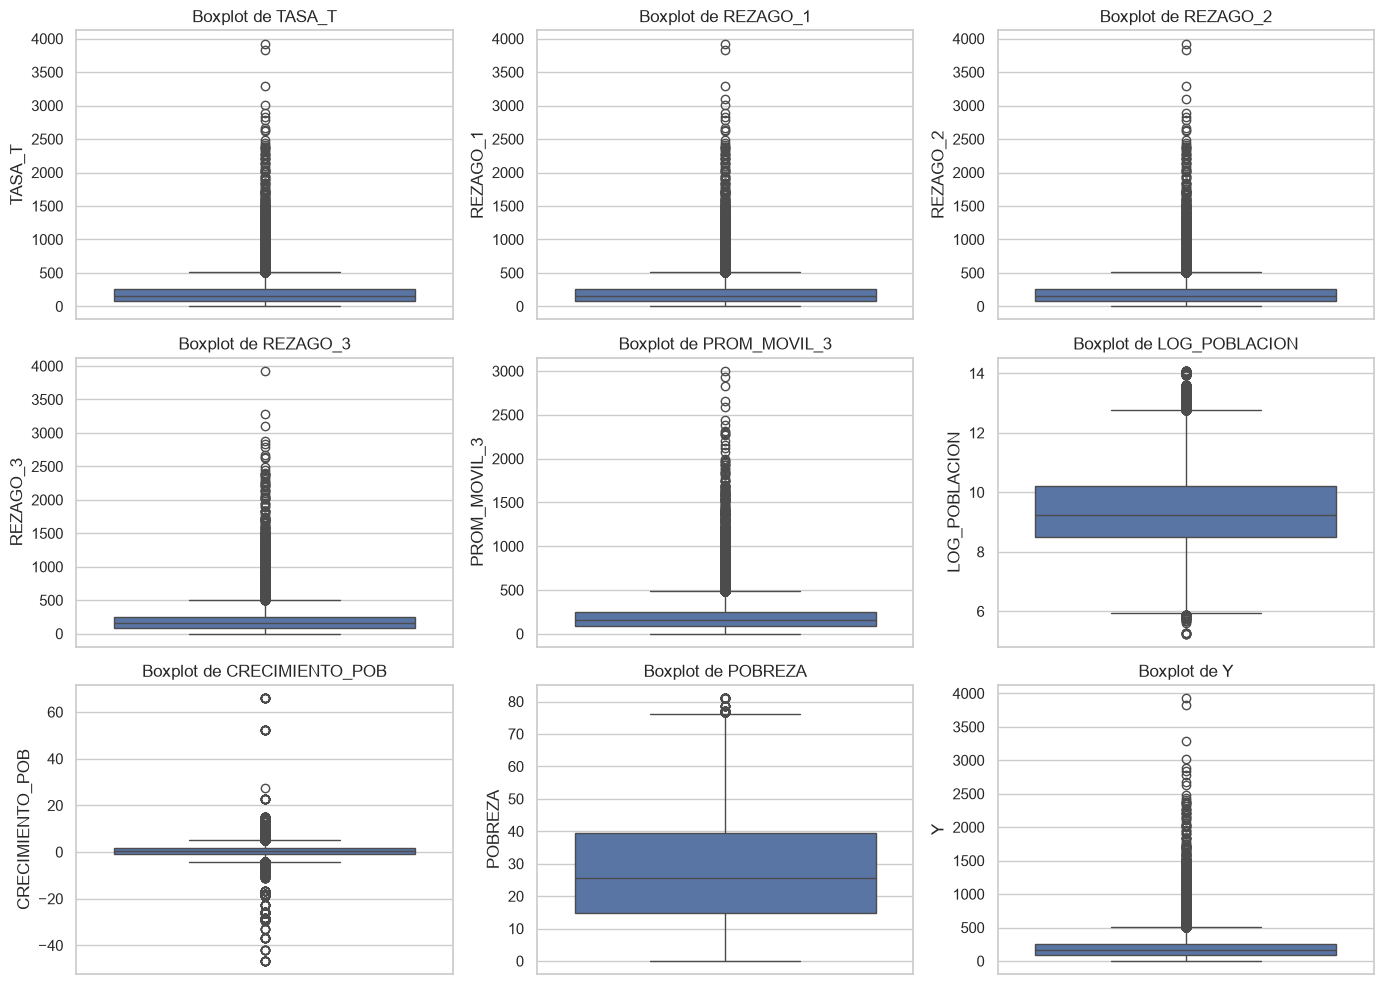

In [20]:
numericals = ['TASA_T', 'REZAGO_1', 'REZAGO_2', 'REZAGO_3', 'PROM_MOVIL_3',
              'LOG_POBLACION', 'CRECIMIENTO_POB', 'POBREZA', 'Y']

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, column in zip(axes.ravel(), numericals):
    sns.boxplot(y=df[column], ax=ax)
    ax.set_title(f'Boxplot de {column}')
plt.tight_layout()
plt.show()

In [21]:
# Porcentaje de valores atipicos segun el criterio del rango intercuartil (IQR)
for columna in numericals:
    Q1 = df[columna].quantile(0.25)
    Q3 = df[columna].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5*IQR
    limite_superior = Q3 + 1.5*IQR
    pct = ((df[columna] < limite_inferior) | (df[columna] > limite_superior)).mean()*100
    print('{}: {:.1f}% de valores atipicos'.format(columna, pct))

TASA_T: 3.6% de valores atipicos
REZAGO_1: 3.6% de valores atipicos
REZAGO_2: 3.6% de valores atipicos
REZAGO_3: 3.6% de valores atipicos
PROM_MOVIL_3: 3.5% de valores atipicos
LOG_POBLACION: 1.7% de valores atipicos
CRECIMIENTO_POB: 4.1% de valores atipicos
POBREZA: 0.2% de valores atipicos
Y: 3.6% de valores atipicos


**Decisión sobre los valores atípicos:** no se recortan.

- El target `Y` no se debe recortar: es justamente lo que se quiere predecir, y recortarlo haría que el error parezca menor de lo que realmente es.
- Las variables de historial son la misma tasa en meses anteriores, por lo que tampoco se recortan.
- Las tasas muy altas son reales: aparecen sobre todo en distritos con poca población, donde pocas denuncias mueven mucho la tasa (en un distrito de 1 000 habitantes, una sola denuncia equivale a 100 por cada 100 000). Este efecto se analiza en la sección 10.

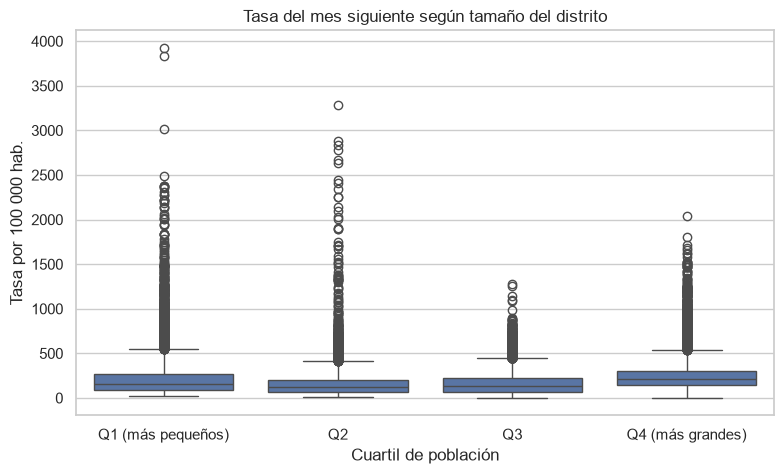

,count,mean,50%,std,max
TAM_POB,,,,,
Q1 (más pequeños),22015.000,212.213,160.256,200.245,3926.282
Q2,21994.000,153.989,119.798,143.817,3289.367
Q3,22009.000,158.584,132.013,120.339,1273.780
Q4 (más grandes),21997.000,244.832,215.155,157.653,2038.753


In [22]:
# La tasa segun el tamaño del distrito (cuartiles de poblacion)
df['TAM_POB'] = pd.qcut(df['LOG_POBLACION'], 4, labels=['Q1 (más pequeños)', 'Q2', 'Q3', 'Q4 (más grandes)'])

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='TAM_POB', y='Y')
plt.title('Tasa del mes siguiente según tamaño del distrito')
plt.xlabel('Cuartil de población')
plt.ylabel('Tasa por 100 000 hab.')
plt.show()

df.groupby('TAM_POB', observed=True)['Y'].describe()[['count', 'mean', '50%', 'std', 'max']]

**Cómo leer la figura y la tabla.** Comparar la desviación estándar (`std`) y el máximo de Q1 con los de Q4. En los distritos más pequeños la tasa es mucho más dispersa: con pocos habitantes, una o dos denuncias de más cambian la tasa en decenas o cientos de puntos. En los distritos grandes la tasa es más estable de un mes a otro. Esta es la razón por la que esperamos que cualquier modelo se equivoque más en distritos pequeños, y lo verificamos en la sección 10.

## 4. Separación en train, validation y test

En clase se usa `train_test_split`, que reparte las filas al azar. Aquí no podemos hacer eso porque los datos tienen orden en el tiempo: si se mezclan al azar, el modelo entrenaría con meses de 2025 para "predecir" meses de 2022, es decir, conocería el futuro (*data leakage*). El error saldría más bajo de lo que sería en el uso real, donde el futuro nunca está disponible. Por eso la separación se hace por año del mes objetivo:

| Conjunto | Años | Uso |
|---|---|---|
| Train | 2018 – 2023 | entrenar los modelos |
| Validation | 2024 | primera comparación de los algoritmos (sección 6) |
| Test | 2025 | evaluación final, una sola vez (sección 8) |

Train y validation juntos (2018–2024) forman los **datos de desarrollo**: sobre ellos se eligen los hiperparámetros y el modelo, con la validación cruzada temporal de la sección 7. El año 2025 no participa en ninguna decisión.

2026 queda fuera porque solo tiene datos hasta julio.

In [23]:
# separa el dataset en atributos (X) y target (y)
X = df[features]
y = df[target]

In [24]:
train = df['ANIO_OBJ'] <= 2023
val = df['ANIO_OBJ'] == 2024
test = df['ANIO_OBJ'] == 2025

X_train, y_train = X[train], y[train]
X_val, y_val = X[val], y[val]
X_test, y_test = X[test], y[test]

print('Training: %d ejemplos. Validation: %d ejemplos. Test: %d ejemplos' % (len(y_train), len(y_val), len(y_test)))

Training: 58685 ejemplos. Validation: 11612 ejemplos. Test: 11313 ejemplos


## 5. Línea base ingenua

La línea base predice que la tasa del mes siguiente será igual a la del mes actual (`TASA_T`). No entrena nada.

**Por qué la necesitamos.** Un MAE suelto no dice si un modelo es bueno o malo. La tasa de un distrito cambia poco de un mes a otro, así que "repetir el último valor" ya es una predicción razonable y difícil de superar. Un modelo solo vale la pena si tiene menos error que esta regla, y eso es exactamente lo que plantea nuestra hipótesis.

**Métricas** (MAE y RMSE están en las mismas unidades que la tasa: denuncias por 100 000 habitantes):

- **MAE** (error absoluto medio): en promedio, por cuántos puntos de tasa se equivoca la predicción. Es nuestra métrica principal porque se interpreta directamente y no se deja dominar por unos pocos errores enormes.
- **RMSE** (raíz del error cuadrático medio): castiga más los errores grandes. Si el RMSE es mucho mayor que el MAE, hay pocos casos con errores muy grandes.
- **R²**: proporción de la variabilidad de la tasa que la predicción logra explicar (1 es perfecto).

In [25]:
y_pred_base = X_val['TASA_T']

print("Linea base en validation (2024)")
print("Mean absolute error:", mean_absolute_error(y_val, y_pred_base))
print("Root mean squared error:", np.sqrt(mean_squared_error(y_val, y_pred_base)))
print("R2 score:", r2_score(y_val, y_pred_base))

Linea base en validation (2024)
Mean absolute error: 68.24531650317383
Root mean squared error: 122.74803344610697
R2 score: 0.5745164741112057


**Cómo interpretar estos números.** Este es el error a vencer. Quien asume que el próximo mes será igual al actual se equivoca, en promedio, por 68.2 denuncias por cada 100 000 habitantes, frente a una tasa media de 210.9 en 2024: un error de alrededor de un tercio de la tasa. El RMSE (122.7) es casi el doble del MAE, lo que indica que hay pocos distritos-mes con errores muy grandes (los saltos de tasa en distritos pequeños). Aun así, la base explica el 57 % de la variabilidad (R² = 0.575), lo que confirma que es un rival exigente.

## 6. Evaluación de los algoritmos

Como primer vistazo, se evalúan los tres algoritmos del trabajo con su configuración por defecto:

    - K-Nearest Neighbors (KNN)
    - Random Forest (RandomForest)
    - Gradient Boosting (GradientBoosting)

KNN predice promediando los distritos-mes más parecidos, y "parecido" se mide con distancias. Si una variable tiene valores en cientos (la tasa) y otra entre −1 y 1 (el seno del mes), la primera decide toda la distancia. Por eso KNN necesita que las variables estén en la misma escala. El escalamiento se pone dentro de un **pipeline** para que la media y la desviación del escalador se calculen solo con los datos de entrenamiento; calcularlas con todos los datos sería otra forma de filtrar información de validación. Los modelos de árboles parten los datos con umbrales por variable, así que no necesitan escalamiento.

In [26]:
# Definimos el pool de algoritmos de ML a evaluar
algos = []
algos.append(('KNN', Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor())])))
algos.append(('RandomForest', RandomForestRegressor(random_state=seed, n_jobs=-1)))
algos.append(('GradientBoosting', GradientBoostingRegressor(random_state=seed)))

Cada algoritmo se entrena con train (2018-2023) y se mide en validation (2024). Además del error total, se guarda el MAE de cada mes de 2024 para ver qué tan estable es cada algoritmo.

In [27]:
results = []
names = []
meses_val = df.loc[val, 'FECHA_OBJ']

# la linea base entra a la comparacion
results.append((y_val - y_pred_base).abs().groupby(meses_val).mean())
names.append('Base ingenua')

# evalua cada algoritmo
for algoname, algo in algos:
    algo.fit(X_train, y_train)
    y_predicted = algo.predict(X_val)
    results.append((y_val - y_predicted).abs().groupby(meses_val).mean())   # MAE de cada mes de 2024
    names.append(algoname)
    print("{}: MAE={:.2f}  RMSE={:.2f}  R2={:.3f}".format(algoname,
          mean_absolute_error(y_val, y_predicted),
          np.sqrt(mean_squared_error(y_val, y_predicted)),
          r2_score(y_val, y_predicted)))

KNN: MAE=64.86  RMSE=108.87  R2=0.665
RandomForest: MAE=60.59  RMSE=102.07  R2=0.706
GradientBoosting: MAE=59.08  RMSE=101.15  R2=0.711


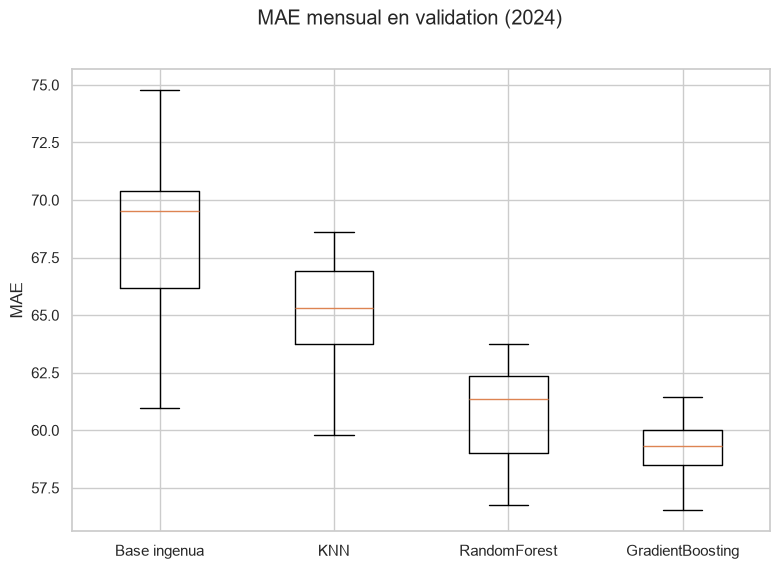

In [28]:
# Muestra graficamente el MAE mensual en validation de los algoritmos evaluados
fig = plt.figure(figsize=[9,6])
fig.suptitle('MAE mensual en validation (2024)')
ax = fig.add_subplot(111)
plt.boxplot(results)
ax.set_xticklabels(names)
ax.set_ylabel('MAE')
plt.show()

**Cómo leer la figura.** Cada caja resume los 12 valores de MAE mensual de 2024. Una caja más baja indica menor error; una caja más angosta indica un comportamiento más estable entre meses.

**Qué concluimos en este punto.** Aun sin ajustar, los tres modelos quedan por debajo de la base ingenua (MAE 68.2): Gradient Boosting 59.1, Random Forest 60.6 y KNN 64.9. Es una primera señal a favor de nuestra hipótesis.

Con valores por defecto, Gradient Boosting queda 1.5 puntos por delante de Random Forest. Sin embargo, esta comparación tiene dos límites: se hizo en un solo año y con modelos sin ajustar. Random Forest por defecto usa árboles sin límite de profundidad y todas las variables en cada división, una configuración que tiende a sobreajustar en datos ruidosos como estos. Por eso no elegimos el modelo aquí, sino en la sección 7, con cada modelo ajustado y evaluado en tres años.

## 7. Optimización de hiperparámetros con validación cruzada temporal

Se usa `GridSearchCV` para probar todas las combinaciones de hiperparámetros de cada modelo. El criterio de selección es el menor MAE.

**Por qué validación cruzada.** En la sección 6 cada modelo se midió en un solo año (2024). Con un solo año no se puede saber si un modelo gana porque es mejor o porque 2024 le resultó favorable. Esto es clave para nuestro trabajo: en los antecedentes revisados Random Forest aparece como el modelo más preciso, pero en una sola partición la diferencia entre Random Forest y Gradient Boosting es de décimas. Para decidir con más evidencia, cada configuración se evalúa en **tres años distintos**.

**Por qué no el `cv=5` de clase.** `cv=5` parte las filas al azar, y con eso volveríamos a entrenar con el futuro. En su lugar usamos una **ventana expansiva**: cada fold entrena únicamente con los años anteriores al año que valida.

| Fold | Entrena con | Valida en |
|---|---|---|
| 1 | 2018 – 2021 | 2022 |
| 2 | 2018 – 2022 | 2023 |
| 3 | 2018 – 2023 | 2024 |

El MAE de una configuración es el promedio de sus tres folds. El tercer fold es la misma partición de la sección 6.

**Detalle de implementación.** A `GridSearchCV` se le pasa la lista explícita de índices (entrenamiento, validación) de cada fold. No usamos `PredefinedSplit` con varios folds porque esa clase entrena cada fold con *todas* las filas que no son de ese fold: al validar en 2022 entrenaría también con 2023 y 2024, que es justamente lo que queremos evitar.

In [29]:
# Datos de desarrollo: todo lo anterior a 2025 (train + validation)
dev = train | val
X_dev, y_dev = X[dev], y[dev]
anios_dev = df.loc[dev, 'ANIO_OBJ'].values

# Ventana expansiva: cada fold entrena SOLO con los años anteriores al año que valida
anios_cv = [2022, 2023, 2024]
cv_temporal = [(np.where(anios_dev < anio)[0], np.where(anios_dev == anio)[0]) for anio in anios_cv]

for anio, (idx_train, idx_val) in zip(anios_cv, cv_temporal):
    print('Fold {}: entrena con 2018-{} ({} filas) | valida en {} ({} filas)'.format(
          anio, anio - 1, len(idx_train), anio, len(idx_val)))

Fold 2022: entrena con 2018-2021 (35562 filas) | valida en 2022 (11598 filas)
Fold 2023: entrena con 2018-2022 (47160 filas) | valida en 2023 (11525 filas)
Fold 2024: entrena con 2018-2023 (58685 filas) | valida en 2024 (11612 filas)


In [30]:
# La linea base en los mismos tres folds (referencia para toda la seccion)
mae_base_folds = [mean_absolute_error(y_dev.iloc[idx_val], X_dev['TASA_T'].iloc[idx_val]) for _, idx_val in cv_temporal]
mae_base_cv = np.mean(mae_base_folds)

print('MAE de la base ingenua por fold:', np.round(mae_base_folds, 2))
print('MAE promedio de la base ingenua en CV temporal:', mae_base_cv)

MAE de la base ingenua por fold: [63.66 68.2  68.25]
MAE promedio de la base ingenua en CV temporal: 66.70135504134483


### 7.1 KNN

Hiperparámetros: número de vecinos, métrica de distancia y esquema de ponderación (`uniform`: todos los vecinos pesan igual; `distance`: los más cercanos pesan más).

In [31]:
pipeline_knn = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor())])

param_grid_knn = {
    'knn__n_neighbors': [5, 10, 20, 50],
    'knn__metric': ['euclidean', 'manhattan'],
    'knn__weights': ['uniform', 'distance']
}

In [33]:
grid_knn = GridSearchCV(pipeline_knn, param_grid_knn, cv=cv_temporal, scoring='neg_mean_absolute_error', refit=False)
grid_knn.fit(X_dev, y_dev)

print("Mejores parámetros KNN (CV temporal):", grid_knn.best_params_)
print("MAE promedio en CV temporal:", -grid_knn.best_score_)

Mejores parámetros KNN (CV temporal): {'knn__metric': 'manhattan', 'knn__n_neighbors': 50, 'knn__weights': 'distance'}
MAE promedio en CV temporal: 58.781037128133484


### 7.2 Random Forest

Hiperparámetros: número de árboles, profundidad máxima, tamaño mínimo de hoja y `max_features`.

Agregamos `max_features` (cuántas variables puede considerar cada división) porque es el hiperparámetro que distingue a Random Forest de un simple promedio de árboles: con `1.0` todos los árboles ven todas las variables y se parecen mucho entre sí; con valores menores los árboles son más distintos y su promedio suele generalizar mejor. Como queremos saber si Random Forest es el mejor modelo para este problema, corresponde darle la oportunidad de ajustarlo.

In [34]:
param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_leaf': [5, 15],
    'max_features': ['sqrt', 0.7, 1.0]
}

In [36]:
grid_rf = GridSearchCV(RandomForestRegressor(random_state=seed, n_jobs=-1), param_grid_rf,
                       cv=cv_temporal, scoring='neg_mean_absolute_error', refit=False, verbose=1)
grid_rf.fit(X_dev, y_dev)

print("Mejores parámetros RF (CV temporal):", grid_rf.best_params_)
print("MAE promedio en CV temporal:", -grid_rf.best_score_)

Fitting 3 folds for each of 36 candidates, totalling 108 fits
Mejores parámetros RF (CV temporal): {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 200}
MAE promedio en CV temporal: 57.99080437576853


### 7.3 Gradient Boosting

Hiperparámetros: número de árboles, profundidad máxima y tamaño mínimo de hoja.

In [37]:
param_grid_gb = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5],
    'min_samples_leaf': [5, 20]
}

In [38]:
grid_gb = GridSearchCV(GradientBoostingRegressor(random_state=seed), param_grid_gb,
                       cv=cv_temporal, scoring='neg_mean_absolute_error', refit=False, verbose=1)
grid_gb.fit(X_dev, y_dev)

print("Mejores parámetros GB (CV temporal):", grid_gb.best_params_)
print("MAE promedio en CV temporal:", -grid_gb.best_score_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Mejores parámetros GB (CV temporal): {'max_depth': 3, 'min_samples_leaf': 20, 'n_estimators': 100}
MAE promedio en CV temporal: 58.68623045773027


### 7.4 Sensibilidad a los hiperparámetros

Se revisa cuánto cambia el MAE promedio del CV temporal al mover los hiperparámetros y cuánto demora entrenar cada modelo.

In [39]:
# Pasamos los resultados de cada busqueda a un DataFrame
cv_knn = pd.DataFrame(grid_knn.cv_results_)
cv_rf = pd.DataFrame(grid_rf.cv_results_)
cv_gb = pd.DataFrame(grid_gb.cv_results_)

for cv in [cv_knn, cv_rf, cv_gb]:
    cv['MAE'] = -cv['mean_test_score']

cv_knn['param_knn__n_neighbors'] = cv_knn['param_knn__n_neighbors'].astype(int)
cv_gb['param_max_depth'] = cv_gb['param_max_depth'].astype(int)

# En RF la profundidad puede ser None (sin limite), asi que se pasa a texto
cv_rf['param_max_depth'] = cv_rf['param_max_depth'].map(lambda d: 'Sin límite' if pd.isna(d) else str(int(d)))
cv_rf['param_max_features'] = cv_rf['param_max_features'].astype(str)

for cv in [cv_rf, cv_gb]:
    cv['param_min_samples_leaf'] = cv['param_min_samples_leaf'].astype(str)
    cv['param_n_estimators'] = cv['param_n_estimators'].astype(str)

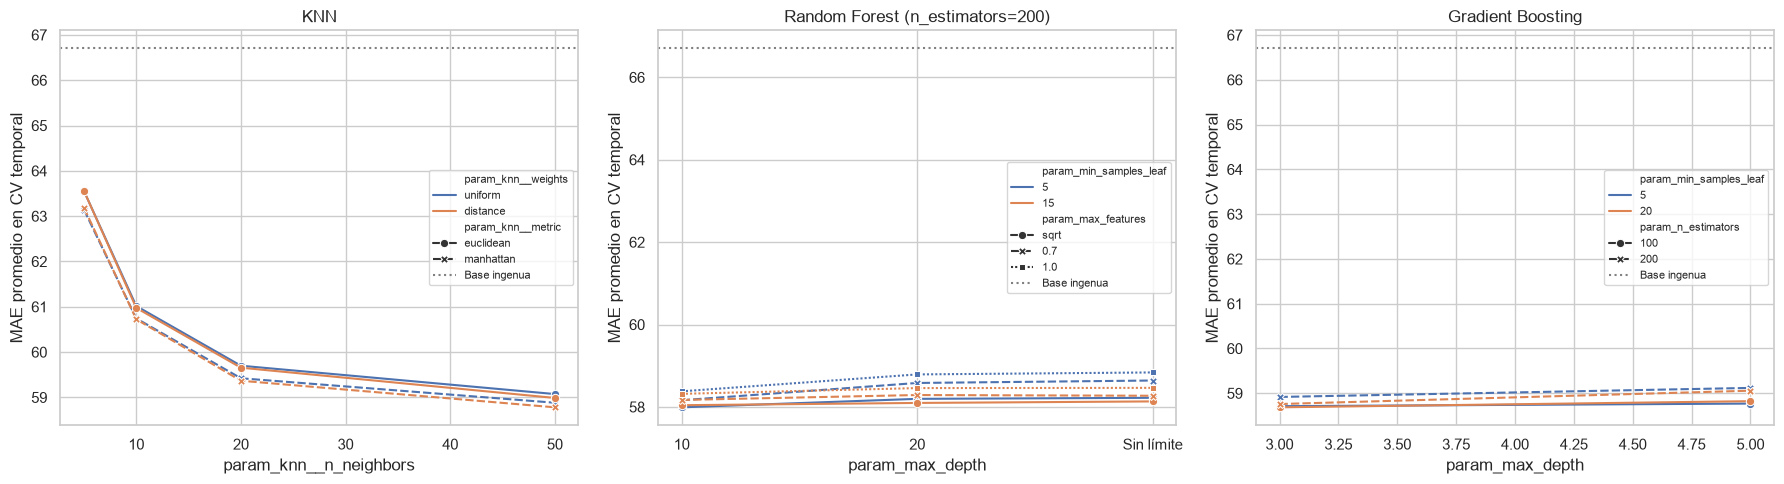

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.lineplot(data=cv_knn, x='param_knn__n_neighbors', y='MAE', hue='param_knn__weights',
             style='param_knn__metric', markers=True, ax=axes[0])
axes[0].set_title('KNN')

# RF tiene 4 hiperparametros: se fija el mejor numero de arboles para que el grafico sea legible
mejor_n = str(grid_rf.best_params_['n_estimators'])
cv_rf_plot = cv_rf[cv_rf['param_n_estimators'] == mejor_n]
sns.lineplot(data=cv_rf_plot, x='param_max_depth', y='MAE', hue='param_min_samples_leaf',
             style='param_max_features', markers=True, ax=axes[1])
axes[1].set_title(f'Random Forest (n_estimators={mejor_n})')

sns.lineplot(data=cv_gb, x='param_max_depth', y='MAE', hue='param_min_samples_leaf',
             style='param_n_estimators', markers=True, ax=axes[2])
axes[2].set_title('Gradient Boosting')

for ax in axes:
    ax.axhline(mae_base_cv, color='gray', linestyle=':', label='Base ingenua')
    ax.set_ylabel('MAE promedio en CV temporal')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [43]:
# Rango de MAE y tiempo de entrenamiento de cada modelo dentro de la busqueda
sensibilidad = pd.DataFrame({
    'Combinaciones': [len(cv_knn), len(cv_rf), len(cv_gb)],
    'MAE minimo': [cv_knn['MAE'].min(), cv_rf['MAE'].min(), cv_gb['MAE'].min()],
    'MAE maximo': [cv_knn['MAE'].max(), cv_rf['MAE'].max(), cv_gb['MAE'].max()],
    'Tiempo de entrenamiento medio (s)': [cv_knn['mean_fit_time'].mean(), cv_rf['mean_fit_time'].mean(), cv_gb['mean_fit_time'].mean()]
}, index=['KNN', 'RandomForest', 'GradientBoosting'])
sensibilidad

,Combinaciones,MAE minimo,MAE maximo,Tiempo de entrenamiento medio (s)
KNN,16,58.781,63.558,0.058
RandomForest,36,57.991,58.884,0.949
GradientBoosting,8,58.686,59.120,12.071


In [44]:
# Efecto de max_features en Random Forest (MAE promedio de las combinaciones con cada valor)
cv_rf.groupby('param_max_features')['MAE'].agg(['mean', 'min'])

,mean,min
param_max_features,,
0.7,58.381,58.163
1.0,58.553,58.318
sqrt,58.131,57.991


**Cómo leer la figura.** Cada punto es una combinación de hiperparámetros y su MAE promedio en los tres folds. Si las líneas de un modelo son casi planas, el modelo es poco sensible a ese hiperparámetro. La línea punteada es la base ingenua en los mismos folds (66.7): todo lo que queda por debajo la mejora.

**Qué encontramos.**

- **Todas las combinaciones superan a la base.** La peor de las 60 configuraciones probadas (KNN con MAE 63.6) sigue 3 puntos por debajo de 66.7. La conclusión del trabajo no depende de haber encontrado la configuración exacta.
- **KNN es el más sensible** (MAE entre 58.8 y 63.6): con pocos vecinos copia el ruido de casos puntuales. Su mejor configuración usa 50 vecinos, distancia Manhattan y ponderación por distancia. Como 50 es el valor más alto que probamos, es posible que con más vecinos mejore un poco más.
- **Random Forest es estable** (57.99 a 58.88): sus 36 combinaciones caben en menos de un punto de MAE. El hiperparámetro que más ayuda es `max_features`: con `sqrt` el MAE promedio es 58.13, con `0.7` es 58.38 y con `1.0` es 58.55. Es decir, obligar a los árboles a ser distintos entre sí mejora el promedio. La mejor configuración (`max_depth=10`, `max_features='sqrt'`, `min_samples_leaf=5`, 200 árboles) es además la de árboles menos profundos: en estos datos conviene un modelo que no se ajuste a casos individuales.
- **Gradient Boosting también es estable** (58.69 a 59.12) y su mejor configuración es la más simple de la cuadrícula (profundidad 3, 100 árboles, hojas de al menos 20). Coincide con lo anterior: más complejidad no ayuda.
- **Costo:** Random Forest entrena en alrededor de 1 segundo por ajuste y Gradient Boosting en 12, porque Random Forest construye sus árboles en paralelo y Gradient Boosting debe hacerlo uno tras otro.

### 7.5 ¿Cuál es el mejor modelo? Comparación en el CV temporal

Aquí se responde la pregunta de fondo: con cada modelo en su mejor configuración, **¿Random Forest es el más adecuado para este problema, o lo es Gradient Boosting?**

Para compararlos con más detalle que un solo promedio, se vuelve a entrenar la mejor configuración de cada modelo en cada fold y se guarda el error de cada predicción. Con eso se obtiene:

- el MAE de cada modelo en cada año (2022, 2023, 2024), para ver si el orden entre modelos se repite o cambia de un año a otro;
- el MAE de cada uno de los 36 meses validados, para contar en cuántos meses gana cada modelo.

Todas estas predicciones son "fuera de muestra": cada mes fue predicho por un modelo que solo vio años anteriores.

In [45]:
# Cada modelo con sus mejores hiperparametros (sin entrenar)
mejores = {
    'KNN': clone(pipeline_knn).set_params(**grid_knn.best_params_),
    'RandomForest': RandomForestRegressor(random_state=seed, n_jobs=-1, **grid_rf.best_params_),
    'GradientBoosting': GradientBoostingRegressor(random_state=seed, **grid_gb.best_params_)
}

# Error absoluto de cada prediccion en los folds de validacion
idx_val_cv = np.concatenate([idx_val for _, idx_val in cv_temporal])
errores_cv = pd.DataFrame({'Base ingenua': (y_dev.iloc[idx_val_cv] - X_dev['TASA_T'].iloc[idx_val_cv]).abs()})

for nombre, modelo in mejores.items():
    errores = []
    for idx_train, idx_val in cv_temporal:
        modelo_fold = clone(modelo).fit(X_dev.iloc[idx_train], y_dev.iloc[idx_train])
        y_pred_fold = modelo_fold.predict(X_dev.iloc[idx_val])
        errores.append((y_dev.iloc[idx_val] - y_pred_fold).abs())
    errores_cv[nombre] = pd.concat(errores)

errores_cv.shape

(34735, 4)

In [46]:
# MAE de cada modelo en cada fold (año de validacion)
cv_comparacion = errores_cv.groupby(df.loc[errores_cv.index, 'ANIO_OBJ']).mean().T
cv_comparacion.columns = ['MAE ' + str(anio) for anio in cv_comparacion.columns]
columnas_folds = list(cv_comparacion.columns)

cv_comparacion['MAE promedio CV'] = cv_comparacion[columnas_folds].mean(axis=1)
cv_comparacion['Desv. entre folds'] = cv_comparacion[columnas_folds].std(axis=1)
cv_comparacion['Mejora vs base (%)'] = (1 - cv_comparacion['MAE promedio CV']/cv_comparacion.loc['Base ingenua', 'MAE promedio CV'])*100

cv_comparacion = cv_comparacion.sort_values('MAE promedio CV')
cv_comparacion.round(3)

,MAE 2022,MAE 2023,MAE 2024,MAE promedio CV,Desv. entre folds,Mejora vs base (%)
RandomForest,55.374,59.759,58.840,57.991,2.313,13.059
GradientBoosting,56.310,60.785,58.963,58.686,2.250,12.016
KNN,56.238,60.761,59.345,58.781,2.313,11.874
Base ingenua,63.661,68.197,68.245,66.701,2.633,0.000


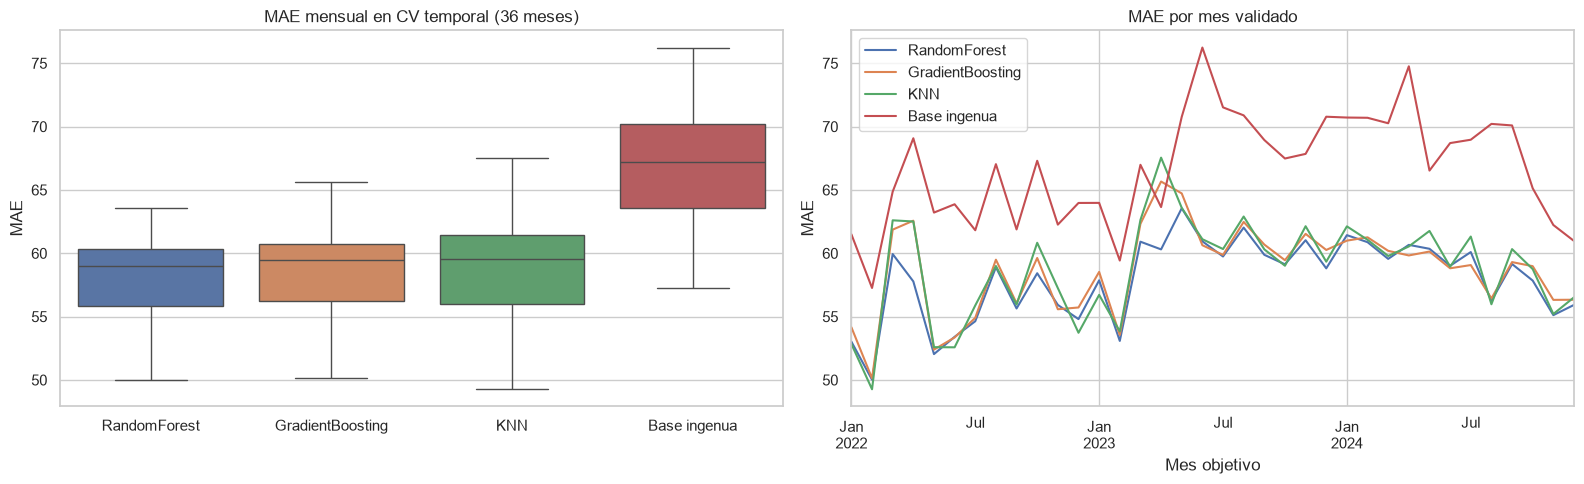

In [47]:
# MAE de cada mes validado (36 meses: 2022, 2023 y 2024)
mae_mensual_cv = errores_cv.groupby(df.loc[errores_cv.index, 'FECHA_OBJ']).mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(data=mae_mensual_cv[cv_comparacion.index], ax=axes[0])
axes[0].set_title('MAE mensual en CV temporal (36 meses)')
axes[0].set_ylabel('MAE')

mae_mensual_cv[cv_comparacion.index].plot(ax=axes[1])
axes[1].set_title('MAE por mes validado')
axes[1].set_xlabel('Mes objetivo')
axes[1].set_ylabel('MAE')

plt.tight_layout()
plt.show()

In [48]:
# En cuantos de los 36 meses gana cada modelo
solo_modelos_cv = mae_mensual_cv.drop(columns='Base ingenua')
print('Meses en los que cada modelo tiene el menor MAE:')
print(solo_modelos_cv.idxmin(axis=1).value_counts())

print()
print('Meses en los que cada modelo supera a la base ingenua (de {}):'.format(len(mae_mensual_cv)))
print(solo_modelos_cv.lt(mae_mensual_cv['Base ingenua'], axis=0).sum())

# Random Forest contra Gradient Boosting, mes a mes
dif_rf_gb = mae_mensual_cv['RandomForest'] - mae_mensual_cv['GradientBoosting']
print()
print('Random Forest vs. Gradient Boosting')
print('  Meses en que gana Random Forest: {} de {}'.format((dif_rf_gb < 0).sum(), len(dif_rf_gb)))
print('  Diferencia media de MAE (RF - GB): {:.3f}'.format(dif_rf_gb.mean()))
print('  Diferencia de MAE promedio CV (RF - GB): {:.3f}'.format(
      cv_comparacion.loc['RandomForest', 'MAE promedio CV'] - cv_comparacion.loc['GradientBoosting', 'MAE promedio CV']))

Meses en los que cada modelo tiene el menor MAE:
RandomForest        22
KNN                  7
GradientBoosting     7
Name: count, dtype: int64

Meses en los que cada modelo supera a la base ingenua (de 36):
KNN                 35
RandomForest        36
GradientBoosting    35
dtype: int64

Random Forest vs. Gradient Boosting
  Meses en que gana Random Forest: 28 de 36
  Diferencia media de MAE (RF - GB): -0.699
  Diferencia de MAE promedio CV (RF - GB): -0.695


In [49]:
# El modelo se elige por el menor MAE promedio en el CV temporal (no se usa el test para elegir)
mejor = cv_comparacion.drop('Base ingenua').index[0]
print('Modelo seleccionado por CV temporal:', mejor)

Modelo seleccionado por CV temporal: RandomForest


**Cómo leer estos resultados.**

- **Tabla por fold:** si un modelo tiene el menor MAE en los tres años, su ventaja es consistente.
- **Desviación entre folds:** indica cuánto cambia el error de un mismo modelo según el año; sirve como vara de medida para las diferencias entre modelos.
- **Conteo de meses:** indica si la ventaja se repite mes a mes o depende de unos pocos meses.

**¿Random Forest es el mejor modelo para este problema?** Con nuestros datos, sí, aunque por un margen pequeño:

- Tiene el menor MAE promedio en el CV temporal: **57.99**, frente a 58.69 de Gradient Boosting y 58.78 de KNN.
- Gana en **los tres años**: 2022 (55.4 contra 56.3), 2023 (59.8 contra 60.8) y 2024 (58.8 contra 59.0). El orden no cambia de un año a otro.
- Es el mejor de los tres modelos en 22 de los 36 meses, y le gana a Gradient Boosting en **28 de 36**.
- Es el único que supera a la base ingenua en los 36 meses (los otros dos, en 35).

**Lo que no se debe exagerar.** La ventaja sobre Gradient Boosting es de 0.70 puntos de MAE (alrededor de 1.2 %), menor que lo que cambia el error de un mismo modelo entre años (desviación de 2.3). Lo correcto es decir que Random Forest tiene una ventaja **pequeña pero consistente**, no que es claramente superior. Los tres modelos tienen una precisión muy parecida, y lo que realmente los separa es la distancia con la base: entre 11.9 % y 13.1 % menos error.

**Relación con los antecedentes.** El resultado coincide con Gupta et al., donde Random Forest fue el modelo más preciso para predecir tasas de criminalidad. También explica lo visto en la sección 6: con valores por defecto parecía mejor Gradient Boosting, pero al ajustar cada modelo y evaluarlo en tres años, Random Forest pasa adelante. Seleccionamos Random Forest por tener el menor error en el CV temporal y, como criterio adicional, por su menor tiempo de entrenamiento (sección 7.4).

## 8. Entrenamiento final y evaluación en test (2025)

Cada modelo se entrena con sus mejores hiperparámetros usando todos los datos de desarrollo (2018-2024) y se evalúa **una sola vez** en test (2025), que no se usó en ninguna decisión anterior.

Se entrena con 2018-2024 y no solo con 2018-2023 porque es la continuación natural de la ventana expansiva: cada fold predijo un año usando todos los anteriores, y para predecir 2025 lo coherente es usar todo lo anterior a 2025. Además, 2024 es el año más parecido a 2025 y dejarlo fuera sería desperdiciar la información más reciente.

El modelo ya fue seleccionado en la sección 7.5. El test no se usa para elegir: sirve para reportar el error que se esperaría en datos nuevos y para comprobar si lo que se vio en el CV se mantiene.

In [50]:
# Datos con los que se entrenan los modelos finales
X_fit, y_fit = X_dev, y_dev

modelos = {nombre: clone(modelo) for nombre, modelo in mejores.items()}

In [51]:
# La linea base en test
y_pred_base_test = X_test['TASA_T']

filas = [{'Modelo': 'Base ingenua',
          'MAE': mean_absolute_error(y_test, y_pred_base_test),
          'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_base_test)),
          'R2': r2_score(y_test, y_pred_base_test)}]

# Entrena cada modelo y predice el conjunto de test
predicciones = {}
for nombre, modelo in modelos.items():
    modelo.fit(X_fit, y_fit)
    predicciones[nombre] = modelo.predict(X_test)
    filas.append({'Modelo': nombre,
                  'MAE': mean_absolute_error(y_test, predicciones[nombre]),
                  'RMSE': np.sqrt(mean_squared_error(y_test, predicciones[nombre])),
                  'R2': r2_score(y_test, predicciones[nombre])})

rf_final = modelos['RandomForest']
gb_final = modelos['GradientBoosting']

In [52]:
resultados = pd.DataFrame(filas).set_index('Modelo').sort_values('MAE')

mae_base = resultados.loc['Base ingenua', 'MAE']
resultados['Mejora MAE vs base (%)'] = (1 - resultados['MAE']/mae_base)*100
resultados['MAE promedio CV'] = cv_comparacion['MAE promedio CV']

resultados.round(3)

,MAE,RMSE,R2,Mejora MAE vs base (%),MAE promedio CV
Modelo,,,,,
RandomForest,53.074,86.046,0.730,13.125,57.991
GradientBoosting,53.293,87.463,0.721,12.767,58.686
KNN,53.398,88.600,0.714,12.595,58.781
Base ingenua,61.092,103.443,0.610,0.000,66.701


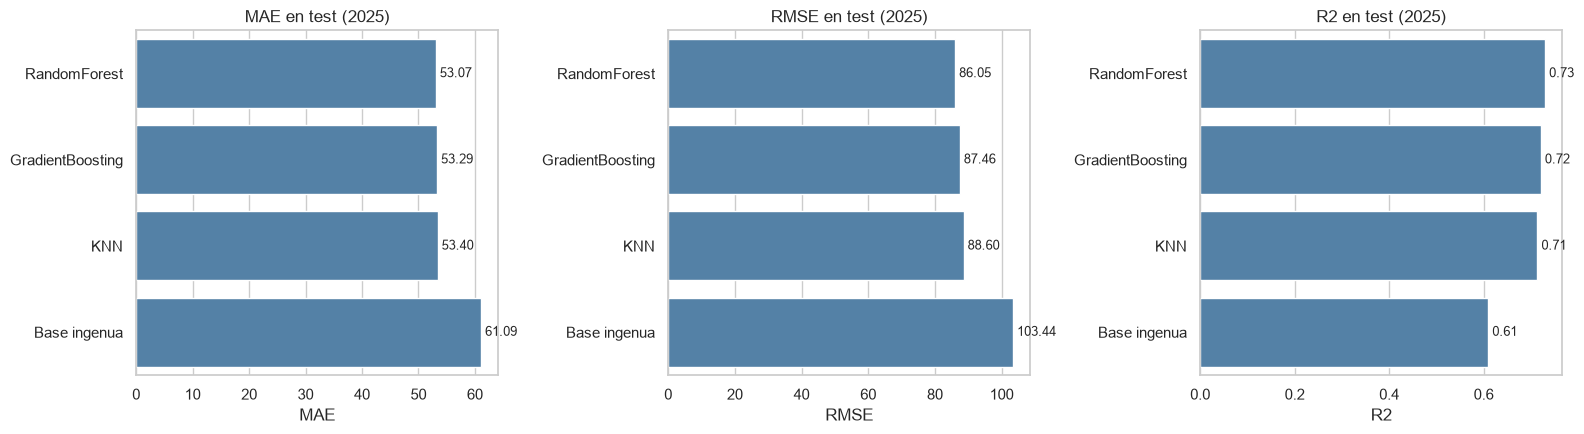

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metrica in zip(axes, ['MAE', 'RMSE', 'R2']):
    sns.barplot(x=resultados[metrica], y=resultados.index, ax=ax, color='steelblue')
    ax.set_title(f'{metrica} en test (2025)')
    ax.set_ylabel('')
    for i, v in enumerate(resultados[metrica]):
        ax.text(v, i, f' {v:.2f}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

In [54]:
# El modelo seleccionado en el CV temporal es el que se analiza en adelante
model = modelos[mejor]
y_predicted = predicciones[mejor]

print('Modelo seleccionado (CV temporal):', mejor)
print('Modelo con menor MAE en test:', resultados.drop('Base ingenua').index[0])

Modelo seleccionado (CV temporal): RandomForest
Modelo con menor MAE en test: RandomForest


**Cómo leer la tabla y la figura.** En MAE y RMSE una barra más corta es mejor; en R² una barra más larga es mejor. `Mejora MAE vs base (%)` es el número que responde la hipótesis.

**Qué encontramos.**

- **La hipótesis se cumple en datos nunca vistos.** En 2025, Random Forest tiene un MAE de **53.07** frente a 61.09 de la base ingenua: **13.1 % menos error**. También mejora el RMSE (86.0 contra 103.4) y el R² (0.730 contra 0.610).
- **El CV temporal estimó bien la mejora.** En el CV la mejora de Random Forest sobre la base fue de 13.06 % y en test es de 13.13 %: prácticamente la misma. El MAE absoluto es más bajo en test (53.1 contra 58.0) porque 2025 fue un año más fácil de predecir para todos, incluida la base (61.1 contra 66.7); por eso la comparación válida es la mejora relativa.
- **El orden se mantiene.** El modelo seleccionado por CV es también el de menor MAE en test, y el orden de los tres modelos es el mismo que en el CV (Random Forest, Gradient Boosting, KNN). No hubo que elegir mirando el test.
- **Los tres modelos son muy parecidos.** Entre el mejor y el peor hay 0.32 puntos de MAE (53.07, 53.29 y 53.40), y entre Random Forest y Gradient Boosting, 0.22. La diferencia relevante es la que hay entre cualquiera de los tres y la base, de unos 8 puntos.

## 9. Valores reales vs. predichos

#### Plotea los valores reales vs los predichos en el conjunto de test

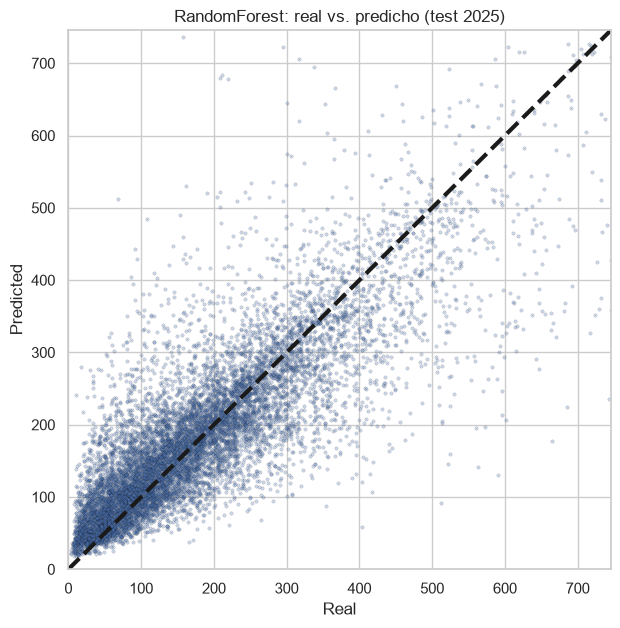

In [55]:
limite = y_test.quantile(0.99)   # se muestra hasta el percentil 99 para que el grafico sea legible

fig, ax = plt.subplots(figsize=[7,7])
ax.scatter(y_test, y_predicted, s=6, alpha=0.3, edgecolors=(0, 0, 0), linewidths=0.2)
ax.plot([0, limite], [0, limite], 'k--', lw=3)
ax.set_xlim(0, limite)
ax.set_ylim(0, limite)
ax.set_xlabel('Real')
ax.set_ylabel('Predicted')
ax.set_title(f'{mejor}: real vs. predicho (test 2025)')
plt.show()

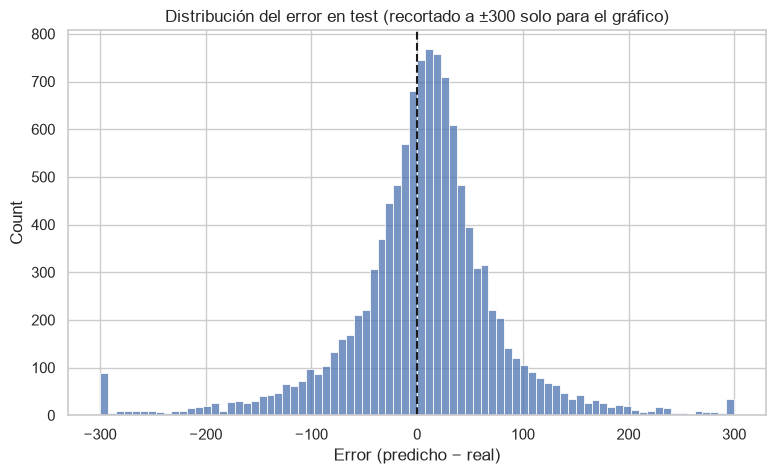

Error medio (sesgo): 4.319325156868565
Error mediano: 9.100367219290803
Error absoluto mediano: 33.68170111598893
Percentil 90 del error absoluto: 117.54928697399158


In [56]:
# Distribucion del error (predicho - real)
errores = y_predicted - y_test

plt.figure(figsize=(9, 5))
sns.histplot(errores.clip(-300, 300), bins=80)
plt.axvline(0, color='k', linestyle='--')
plt.title('Distribución del error en test (recortado a ±300 solo para el gráfico)')
plt.xlabel('Error (predicho − real)')
plt.show()

print('Error medio (sesgo):', errores.mean())
print('Error mediano:', errores.median())
print('Error absoluto mediano:', errores.abs().median())
print('Percentil 90 del error absoluto:', errores.abs().quantile(0.90))

**Cómo leer las figuras.** En el primer gráfico, los puntos sobre la línea punteada son predicciones perfectas; cuanto más dispersos, mayor el error. Cuando la tasa real es muy alta, los puntos tienden a quedar por debajo de la línea: el modelo subestima los picos, lo que es esperable porque un salto brusco de un mes no se puede anticipar solo con el historial.

En el segundo, un histograma centrado en 0 indica que el modelo no tiende a sobrestimar ni a subestimar.

**Qué encontramos.**

- **Sesgo pequeño hacia arriba.** El error medio es +4.3 y el mediano +9.1: el modelo sobrestima ligeramente. La explicación más probable es que la tasa bajó en 2025 (media de 189.0, contra 210.9 en 2024) y el modelo aprendió con años de tasas más altas. Frente a un MAE de 53, este sesgo es menor.
- **El caso típico es mejor que el promedio.** La mitad de las predicciones se equivoca por menos de 33.7 puntos, bastante menos que el MAE (53.1). El MAE está inflado por una minoría de casos: el 10 % de las predicciones con mayor error se equivoca por más de 117.5 puntos. La sección 10 muestra que esos casos se concentran en los distritos pequeños.

## 10. Análisis del error: ¿el modelo funciona igual en todos los casos?

Un MAE global puede esconder que el modelo funciona bien en un tipo de distrito y mal en otro. Aquí se desglosa el error del modelo seleccionado por tamaño del distrito, nivel de pobreza, mes y distrito, comparándolo siempre con la base ingenua. Esto también importa para el uso responsable del modelo: indica dónde sus predicciones son menos confiables.

In [57]:
df_test = df[test].copy()
df_test['ERROR_ABS'] = (y_predicted - y_test).abs()
df_test['ERROR_ABS_BASE'] = (y_pred_base_test - y_test).abs()

df_test['TAM_POB'] = pd.qcut(df_test['LOG_POBLACION'], 4, labels=['Q1 (más pequeños)', 'Q2', 'Q3', 'Q4 (más grandes)'])
df_test['NIVEL_POBREZA'] = pd.qcut(df_test['POBREZA'], 3, labels=['Baja', 'Media', 'Alta'])

In [58]:
# Error segun el tamaño del distrito
por_tam = df_test.groupby('TAM_POB', observed=True).agg(n=('Y', 'size'),
                                                         tasa_media=('Y', 'mean'),
                                                         MAE_modelo=('ERROR_ABS', 'mean'),
                                                         MAE_base=('ERROR_ABS_BASE', 'mean'))
por_tam['Mejora vs base (%)'] = (1 - por_tam['MAE_modelo']/por_tam['MAE_base'])*100
por_tam['MAE / tasa media (%)'] = por_tam['MAE_modelo']/por_tam['tasa_media']*100
por_tam

,n,tasa_media,MAE_modelo,MAE_base,Mejora vs base (%),MAE / tasa media (%)
TAM_POB,,,,,,
Q1 (más pequeños),2833,214.782,93.102,111.322,16.367,43.347
Q2,2829,150.129,50.988,57.778,11.752,33.963
Q3,2823,151.839,36.649,41.263,11.182,24.137
Q4 (más grandes),2828,239.292,31.458,33.884,7.160,13.146


In [59]:
# Error segun el nivel de pobreza
por_pobreza = df_test.groupby('NIVEL_POBREZA', observed=True).agg(n=('Y', 'size'),
                                                                   tasa_media=('Y', 'mean'),
                                                                   MAE_modelo=('ERROR_ABS', 'mean'),
                                                                   MAE_base=('ERROR_ABS_BASE', 'mean'))
por_pobreza['Mejora vs base (%)'] = (1 - por_pobreza['MAE_modelo']/por_pobreza['MAE_base'])*100
por_pobreza['MAE / tasa media (%)'] = por_pobreza['MAE_modelo']/por_pobreza['tasa_media']*100
por_pobreza

,n,tasa_media,MAE_modelo,MAE_base,Mejora vs base (%),MAE / tasa media (%)
NIVEL_POBREZA,,,,,,
Baja,3771,261.408,55.432,62.473,11.269,21.205
Media,3775,192.183,57.375,65.735,12.717,29.854
Alta,3767,113.430,46.403,55.059,15.721,40.909


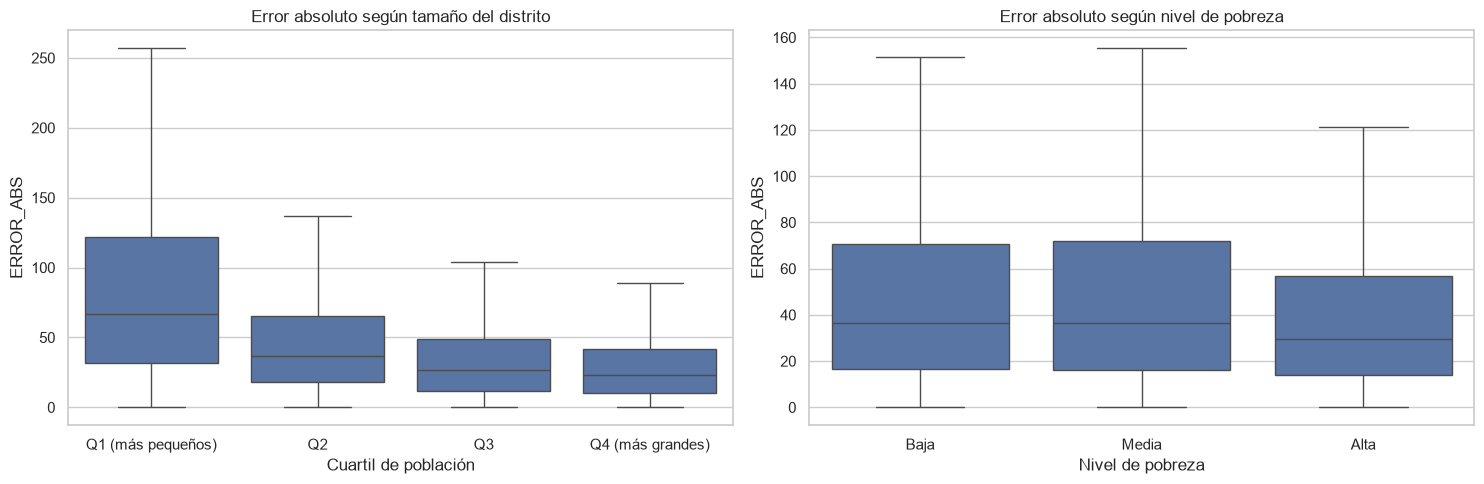

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=df_test, x='TAM_POB', y='ERROR_ABS', showfliers=False, ax=axes[0])
axes[0].set_title('Error absoluto según tamaño del distrito')
axes[0].set_xlabel('Cuartil de población')

sns.boxplot(data=df_test, x='NIVEL_POBREZA', y='ERROR_ABS', showfliers=False, ax=axes[1])
axes[1].set_title('Error absoluto según nivel de pobreza')
axes[1].set_xlabel('Nivel de pobreza')

plt.tight_layout()
plt.show()

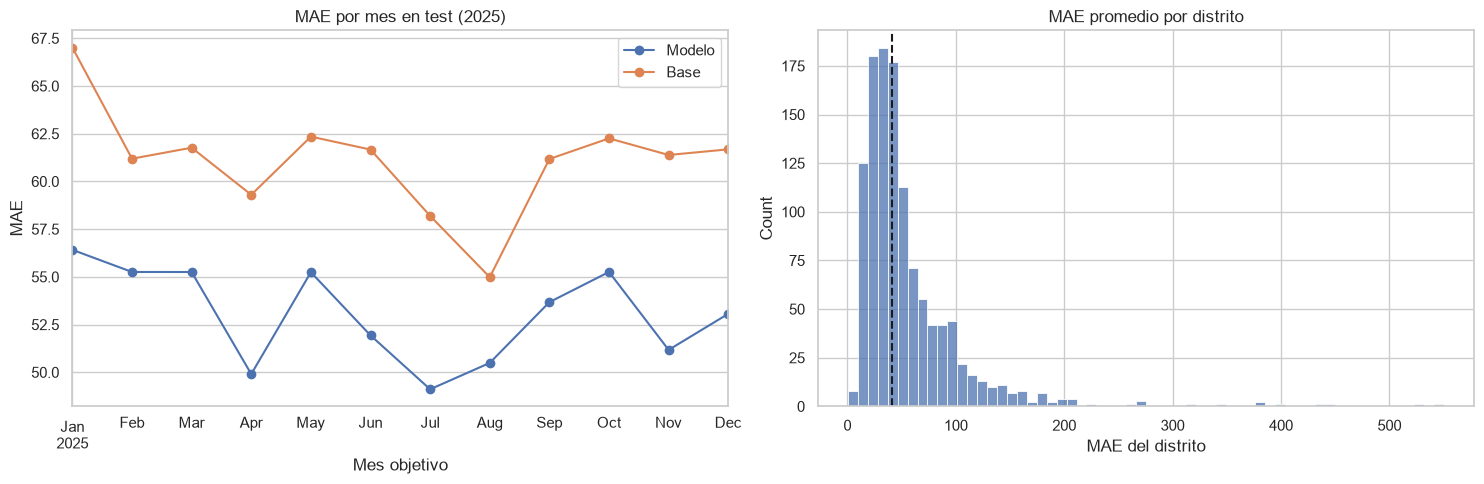

Mediana del MAE por distrito: 41.46879411377552
Distritos donde el modelo supera a la base: 70.3%
Meses donde el modelo supera a la base: 12 de 12


In [61]:
# Error por mes y por distrito
mae_mes = df_test.groupby('FECHA_OBJ').agg(Modelo=('ERROR_ABS', 'mean'), Base=('ERROR_ABS_BASE', 'mean'))
mae_distrito = df_test.groupby('UBIGEO').agg(Modelo=('ERROR_ABS', 'mean'), Base=('ERROR_ABS_BASE', 'mean'))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

mae_mes.plot(marker='o', ax=axes[0])
axes[0].set_title('MAE por mes en test (2025)')
axes[0].set_xlabel('Mes objetivo')
axes[0].set_ylabel('MAE')

sns.histplot(mae_distrito['Modelo'], bins=60, ax=axes[1])
axes[1].axvline(mae_distrito['Modelo'].median(), color='k', linestyle='--')
axes[1].set_title('MAE promedio por distrito')
axes[1].set_xlabel('MAE del distrito')

plt.tight_layout()
plt.show()

print('Mediana del MAE por distrito:', mae_distrito['Modelo'].median())
print('Distritos donde el modelo supera a la base: {:.1f}%'.format((mae_distrito['Modelo'] < mae_distrito['Base']).mean()*100))
print('Meses donde el modelo supera a la base: {} de {}'.format((mae_mes['Modelo'] < mae_mes['Base']).sum(), len(mae_mes)))

**Cómo leer estas tablas y figuras.** `MAE / tasa media (%)` pone el error en proporción a la tasa de cada grupo, y `Mejora vs base (%)` muestra si la ventaja sobre la base se mantiene en todos los grupos.

**Qué encontramos.**

- **El error depende mucho del tamaño del distrito.** En el cuartil de distritos más pequeños el MAE es 93.1, y en el de los más grandes, 31.5: tres veces menos. En proporción a la tasa, el error es de 43 % en Q1 y de 13 % en Q4. En distritos grandes el modelo es bastante preciso; en los pequeños, una o dos denuncias de más cambian la tasa en decenas de puntos y eso no se puede anticipar.
- **El modelo supera a la base en todos los grupos, y más donde hay más ruido.** La mejora es de 16.4 % en Q1 y baja hasta 7.2 % en Q4. La base ingenua copia el ruido del último mes; el modelo lo suaviza, y eso rinde más justo donde la tasa es más inestable.
- **Por pobreza ocurre algo parecido.** En los distritos de pobreza alta el MAE absoluto es el más bajo (46.4) porque sus tasas son bajas (media de 113.4), pero en proporción es el más alto (41 %, contra 21 % en pobreza baja). La mejora sobre la base es mayor ahí (15.7 %). Hay que tener presente que pobreza y tamaño están relacionados: muchos distritos pobres son también pequeños.
- **La mejora es general, no de unos pocos casos.** El modelo supera a la base en los 12 meses de 2025 y en el 70.3 % de los distritos. En el 29.7 % restante la regla simple funcionó igual o mejor, así que la mejora es un resultado promedio y no una garantía para cada distrito. La mediana del MAE por distrito es 41.5.

**Implicancia.** Las predicciones para distritos pequeños tienen mucha más incertidumbre. Esto conecta con las implicancias éticas del informe: no deberían usarse para comparar o señalar distritos pequeños sin revisión humana.

## 11. Importancia de variables

Los modelos de árboles calculan cuánto aporta cada variable a las predicciones (`feature_importances_`): cuánto reduce el error cada variable en las divisiones donde se usa, sumado sobre todos los árboles. Los valores de cada modelo suman 1.

In [62]:
importancia_df = pd.DataFrame({
    'Feature': features,
    'RandomForest': rf_final.feature_importances_,
    'GradientBoosting': gb_final.feature_importances_
}).set_index('Feature').sort_values('GradientBoosting')

print(importancia_df.sort_values('GradientBoosting', ascending=False))

                 RandomForest  GradientBoosting
Feature                                        
PROM_MOVIL_3            0.331             0.740
TASA_T                  0.269             0.173
REZAGO_3                0.076             0.047
LOG_POBLACION           0.025             0.013
REZAGO_2                0.111             0.008
POBREZA                 0.021             0.008
REZAGO_1                0.149             0.006
MES_SIN                 0.004             0.003
CRECIMIENTO_POB         0.011             0.002
MES_COS                 0.003             0.002


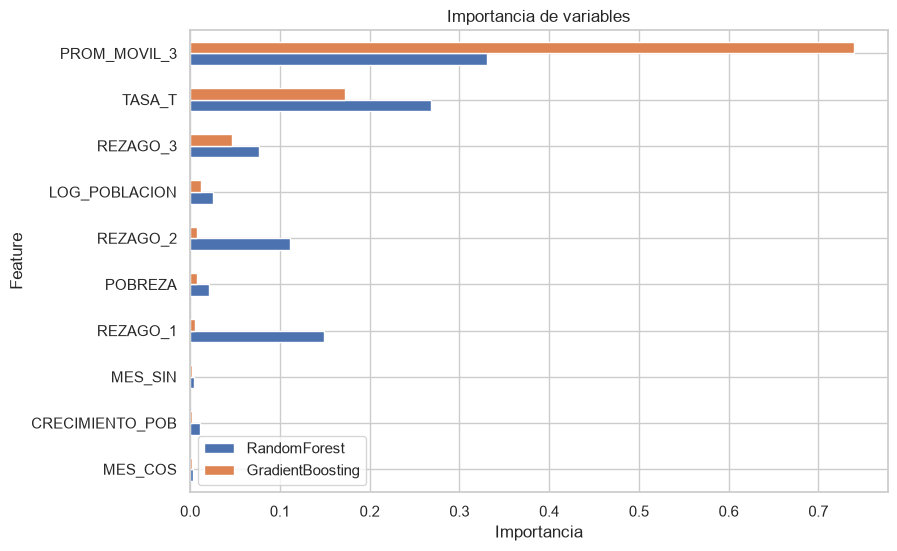

In [63]:
importancia_df.plot(kind='barh', figsize=[9,6])
plt.title('Importancia de variables')
plt.xlabel('Importancia')
plt.show()

#### ¿Qué aporta cada grupo de variables?

La importancia anterior tiene una limitación: cuando varias variables están muy correlacionadas (como las cinco de historial), el modelo puede repartir la importancia entre ellas de forma arbitraria. Para confirmar qué aporta cada grupo, se vuelve a entrenar el modelo seleccionado quitando un grupo de variables a la vez y se mide cuánto empeora el MAE en test. Si quitar un grupo no cambia el error, ese grupo no estaba aportando.

In [64]:
grupos = {
    'historial': ['TASA_T', 'REZAGO_1', 'REZAGO_2', 'REZAGO_3', 'PROM_MOVIL_3'],
    'estacionalidad': ['MES_SIN', 'MES_COS'],
    'demografia': ['LOG_POBLACION', 'CRECIMIENTO_POB'],
    'pobreza': ['POBREZA']
}

# Configuraciones a probar
configuraciones = {'Todas las variables': features}
for grupo, columnas in grupos.items():
    configuraciones['Sin ' + grupo] = [c for c in features if c not in columnas]
configuraciones['Solo historial'] = grupos['historial']

In [65]:
filas = []
for nombre, columnas in configuraciones.items():
    modelo = clone(model)   # copia sin entrenar del modelo seleccionado
    modelo.fit(X_fit[columnas], y_fit)
    y_pred = modelo.predict(X_test[columnas])
    filas.append({'Configuracion': nombre,
                  'n_variables': len(columnas),
                  'MAE': mean_absolute_error(y_test, y_pred),
                  'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
                  'R2': r2_score(y_test, y_pred)})

ablacion = pd.DataFrame(filas).set_index('Configuracion')
ablacion['Cambio de MAE vs todas'] = ablacion['MAE'] - ablacion.loc['Todas las variables', 'MAE']
ablacion.round(3)

,n_variables,MAE,RMSE,R2,Cambio de MAE vs todas
Configuracion,,,,,
Todas las variables,10,53.074,86.046,0.730,0.000
Sin historial,5,80.986,120.454,0.471,27.912
Sin estacionalidad,8,53.147,86.170,0.729,0.073
Sin demografia,8,53.478,87.447,0.721,0.404
Sin pobreza,9,53.293,86.507,0.727,0.219
Solo historial,5,53.860,88.306,0.716,0.786


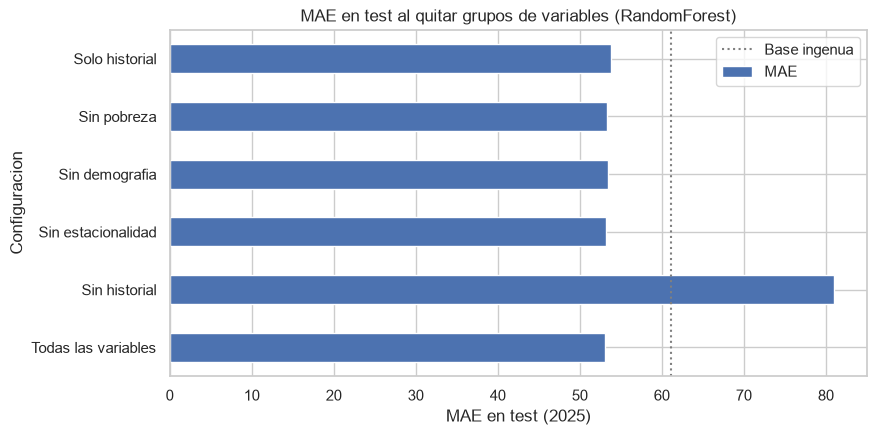

In [66]:
ablacion['MAE'].plot(kind='barh', figsize=[9,4.5])
plt.axvline(mae_base, color='gray', linestyle=':', label='Base ingenua')
plt.title(f'MAE en test al quitar grupos de variables ({mejor})')
plt.xlabel('MAE en test (2025)')
plt.legend()
plt.show()

**Cómo leer la figura y la tabla.** Si al quitar un grupo el MAE casi no cambia, ese grupo aporta poco; si sube mucho, el modelo depende de él. La columna `Cambio de MAE vs todas` lo resume.

**Qué encontramos.**

- **El historial lo es casi todo.** Las cinco variables de historial suman el 94 % de la importancia en Random Forest y el 97 % en Gradient Boosting. Al quitarlas, el MAE sube de 53.1 a **81.0**, peor incluso que la base ingenua (61.1): población, pobreza y mes por sí solos no alcanzan para predecir la tasa.
- **Los dos modelos reparten la importancia de forma distinta.** Gradient Boosting la concentra en `PROM_MOVIL_3` (0.74), mientras que Random Forest la distribuye entre el promedio móvil (0.33), la tasa actual (0.27) y los tres rezagos. Esto se debe a que esas variables están muy correlacionadas entre sí (sección 3) y a que Random Forest, con `max_features='sqrt'`, obliga a cada división a elegir entre un subconjunto de ellas. No significa que un rezago "importe más" en un modelo que en otro.
- **Las demás variables aportan poco, pero algo.** Usando solo el historial el MAE es 53.86, apenas 0.79 puntos más (1.5 %) que con todas las variables. Por separado, quitar demografía sube el MAE en 0.40, quitar pobreza en 0.22 y quitar estacionalidad en 0.07.
- **Por qué pobreza y población pesan tan poco.** No es que no se relacionen con las denuncias: la pobreza tiene una correlación de −0.41 con la tasa. Ocurre que la pobreza es un dato fijo de 2018 por distrito y la población cambia muy lento, así que su efecto ya está contenido en el nivel histórico de la tasa de cada distrito. Una vez que el modelo conoce el historial, esas variables casi no agregan información nueva.

**Relación con la hipótesis.** Nuestra hipótesis menciona rezagos, población, crecimiento y pobreza. Los resultados permiten precisarla: la reducción del error frente a la base se explica casi por completo por el historial de denuncias (varios rezagos y su promedio, en lugar de solo el último mes); las variables sociodemográficas tienen un aporte marginal.

## 12. Resumen para el informe

Esta celda imprime los números principales para pasarlos a las tablas y a la discusión de la sección 4 del informe.

In [67]:
print('DATOS')
print('  Filas modelables: {} | distritos: {}'.format(len(df), df['UBIGEO'].nunique()))
print('  Training: {} | Validation: {} | Test: {}'.format(len(y_train), len(y_val), len(y_test)))
print('  Tasa media real en test: {:.1f} | mediana: {:.1f}'.format(y_test.mean(), y_test.median()))

print()
print('MEJORES HIPERPARAMETROS (CV temporal: valida en 2022, 2023 y 2024)')
print('  KNN:', grid_knn.best_params_)
print('  RandomForest:', grid_rf.best_params_)
print('  GradientBoosting:', grid_gb.best_params_)

print()
print('RESULTADOS EN CV TEMPORAL')
print(cv_comparacion.round(2))

print()
print('RESULTADOS EN TEST (2025)')
print(resultados.round(2))

print()
print('Modelo seleccionado por CV temporal: {} | MAE en test {:.2f} vs. base {:.2f} ({:.1f}% de mejora)'.format(
      mejor, resultados.loc[mejor, 'MAE'], mae_base, resultados.loc[mejor, 'Mejora MAE vs base (%)']))

solo_modelos = resultados.drop('Base ingenua')
print('Diferencia de MAE en test entre el mejor y el peor de los tres modelos: {:.2f}'.format(
      solo_modelos['MAE'].max() - solo_modelos['MAE'].min()))
print('Diferencia de MAE entre Random Forest y Gradient Boosting: {:.2f} en CV | {:.2f} en test'.format(
      abs(cv_comparacion.loc['RandomForest', 'MAE promedio CV'] - cv_comparacion.loc['GradientBoosting', 'MAE promedio CV']),
      abs(resultados.loc['RandomForest', 'MAE'] - resultados.loc['GradientBoosting', 'MAE'])))

DATOS
  Filas modelables: 88015 | distritos: 1440
  Training: 58685 | Validation: 11612 | Test: 11313
  Tasa media real en test: 189.0 | mediana: 152.3

MEJORES HIPERPARAMETROS (CV temporal: valida en 2022, 2023 y 2024)
  KNN: {'knn__metric': 'manhattan', 'knn__n_neighbors': 50, 'knn__weights': 'distance'}
  RandomForest: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 200}
  GradientBoosting: {'max_depth': 3, 'min_samples_leaf': 20, 'n_estimators': 100}

RESULTADOS EN CV TEMPORAL
                  MAE 2022  MAE 2023  MAE 2024  MAE promedio CV  \
RandomForest        55.370    59.760    58.840           57.990   
GradientBoosting    56.310    60.790    58.960           58.690   
KNN                 56.240    60.760    59.340           58.780   
Base ingenua        63.660    68.200    68.250           66.700   

                  Desv. entre folds  Mejora vs base (%)  
RandomForest                  2.310              13.060  
GradientBoosting             

## Conclusiones

- **La hipótesis se cumple.** Los tres modelos reducen el error frente a la línea base que usa la tasa del mes anterior. En el año de prueba (2025), Random Forest tiene un MAE de 53.07 denuncias por 100 000 habitantes frente a 61.09 de la base: **13.1 % menos error**. La mejora es casi idéntica en la validación cruzada temporal de 2022 a 2024 (13.1 %), se da en los 36 meses validados y en los 12 meses de prueba.

- **Random Forest es el modelo seleccionado, con una ventaja pequeña pero consistente.** Tiene el menor MAE promedio en el CV temporal (57.99, frente a 58.69 de Gradient Boosting y 58.78 de KNN), gana en los tres años validados, supera a Gradient Boosting en 28 de 36 meses y también es el mejor en 2025. El resultado coincide con los antecedentes que reportan a Random Forest como el modelo más preciso. Sin embargo, la diferencia con Gradient Boosting es de solo 0.70 puntos en CV y 0.22 en test: los tres modelos tienen una precisión muy parecida y no corresponde afirmar que uno es claramente superior.

- **El ajuste y la forma de validar cambian la conclusión.** Con valores por defecto y un solo año de validación, Gradient Boosting parecía mejor. Al ajustar los hiperparámetros y evaluar en tres años, Random Forest pasa adelante. Una comparación entre modelos sin ajustar o en una sola partición puede llevar a elegir mal.

- **El modelo es menos confiable en distritos pequeños.** El MAE es 93.1 en el cuartil de distritos más pequeños y 31.5 en el de los más grandes (43 % y 13 % de la tasa media, respectivamente). El modelo supera a la base en todos los grupos y en el 70.3 % de los distritos, pero sus predicciones para distritos pequeños tienen mucha incertidumbre.

- **La mejora viene del historial de denuncias.** Sin las variables de historial el MAE sube a 81.0, peor que la base. Usando solo el historial es 53.86, apenas 0.79 puntos más que con todas las variables. Población, crecimiento, pobreza y estacionalidad aportan poco porque su efecto ya está contenido en el nivel histórico de cada distrito.

- **Limitaciones.**
  - Los resultados representan denuncias registradas, no la totalidad de delitos ocurridos.
  - Solo entran al modelo 1 440 de los 1 839 distritos del dataset: los que registran denuncias en meses consecutivos. Los distritos con registros esporádicos quedan fuera.
  - La pobreza es un dato de 2018 que no cambia en el tiempo.
  - El modelo predice solo un mes hacia adelante y sobrestima ligeramente la tasa de 2025 (+4.3 en promedio), un año en que la tasa bajó respecto a 2024.